# M3 — Crack Segmentation Baseline + Colab GPU Training

**Objective**: Implement and evaluate the first reproducible binary crack-segmentation baseline (U-Net with ResNet-34 encoder) using audited dataset manifests, with full evaluation exclusions and documented limitations.

**Dataset eligibility (audited)**:
- Crack-Seg: use duplicate-exclusion manifest; exclude exact duplicate pair from scored test (111 images scored). Preserve the 6 unresolved near-duplicate cross-split pairs as a documented evaluation limitation (see `docs/dataset-audit/near_duplicate_inspection.md`).
- Concrete400 segmentation: use only the segmentation subset (`Segmentation/Image` + `Segmentation/Masks`); apply binary threshold `>127` (evidence documented in M1 audit). Do not mix classification images.
- Façade dataset: **excluded from this B1 experiment** (scene leakage: all 15 valid scenes overlap with train; licence/provenance unverified — see `engineering_decisions.md` DSET-002 / DSET-008).

**Safety / scope boundary**:
- This milestone produces a segmentation baseline only. It does **not** establish physical crack width, depth, or structural severity. Physical measurement requires scale calibration; structural severity requires validated engineering criteria beyond image segmentation.

In [1]:
# ------------------------------------------------------------------
# Section 2: Detect Colab environment and print versions
# ------------------------------------------------------------------
import sys, platform
print('Python version:', sys.version)
print('Platform:', platform.platform())
try:
    import torch
    print('PyTorch version:', torch.__version__)
    import torchvision
    print('Torchvision version:', torchvision.__version__)
    cuda_available = torch.cuda.is_available()
    print('torch.cuda.is_available():', cuda_available)
    if cuda_available:
        print('GPU name:', torch.cuda.get_device_name(0))
        print('GPU memory (approx):', torch.cuda.get_device_properties(0).total_memory / 1e9, 'GB')
except Exception as exc:
    print('PyTorch import error:', exc)
    cuda_available = False

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
PyTorch version: 2.11.0+cpu
Torchvision version: 0.26.0+cpu
torch.cuda.is_available(): False


## 1. Select and configure GPU runtime

Before running the full experiment, confirm the runtime is set to GPU:
- In Colab: `Runtime > Change runtime type > Hardware accelerator > GPU`
- If `torch.cuda.is_available()` is `False` below, restart with GPU selected.

If GPU is unavailable, the notebook will warn and stop rather than launching a long CPU run silently (see Section 9 failure handling).

In [2]:
if not cuda_available:
    raise RuntimeError(
        'GPU is unavailable. Please change runtime to GPU (Runtime > Change runtime type > GPU) and re-run this cell.'
    )
print('GPU confirmed. Proceeding with GPU-enabled workflow.')

RuntimeError: GPU is unavailable. Please change runtime to GPU (Runtime > Change runtime type > GPU) and re-run this cell.

## 2. Obtain the project source reproducibly

The project is not a public Git repository. Transfer the local source to Colab using one of these reproducible options:

**Option A — Source archive (recommended):**
1. Locally, run: `python scripts/package_project_source.py` (or manually zip `src/`, `tests/`, `configs/`, `scripts/`, `docs/`, `notebooks/`, excluding `.venv`, caches, raw datasets unless needed).
2. Upload the archive to Colab (`Files > Upload`) or to Google Drive.
3. Extract to `/content/project/`.

**Option B — Drive mount:**
- Mount Drive, place the source folder in `MyDrive/crack-detection/`, and symlink or add to `PYTHONPATH` below.

**Excluded from archive (documented):** `.venv/`, `__pycache__/`, `.pytest_cache/`, temporary files, secrets (`.env`), raw dataset files unless explicitly required.

In [3]:
from google.colab import drive
from pathlib import Path
import json

drive.mount("/content/drive")

DRIVE_ROOT = Path("/content/drive/MyDrive/CrackDetection")

paths_to_check = [
    DRIVE_ROOT / "project" / "src" / "crack_detection" / "dataset_loader.py",
    DRIVE_ROOT / "project" / "scripts" / "generate_full_manifests.py",
    DRIVE_ROOT / "data" / "crack-seg" / "images" / "train",
    DRIVE_ROOT / "data" / "crack-seg" / "labels" / "train",
    DRIVE_ROOT / "manifests" / "crack-seg_train_manifest.json",
    DRIVE_ROOT / "manifests" / "crack-seg_val_manifest.json",
    DRIVE_ROOT / "outputs",
]

for path in paths_to_check:
    print(f'{"OK      " if path.exists() else "MISSING "} {path}')

train_images = DRIVE_ROOT / "data" / "crack-seg" / "images" / "train"
if train_images.exists():
    print("\nTraining images found:", len(list(train_images.glob("*.jpg"))))

manifest_path = DRIVE_ROOT / "manifests" / "crack-seg_train_manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text(encoding="utf-8"))
    print("Training manifest records:", len(manifest.get("records", [])))

Mounted at /content/drive
OK       /content/drive/MyDrive/CrackDetection/project/src/crack_detection/dataset_loader.py
OK       /content/drive/MyDrive/CrackDetection/project/scripts/generate_full_manifests.py
OK       /content/drive/MyDrive/CrackDetection/data/crack-seg/images/train
OK       /content/drive/MyDrive/CrackDetection/data/crack-seg/labels/train
OK       /content/drive/MyDrive/CrackDetection/manifests/crack-seg_train_manifest.json
OK       /content/drive/MyDrive/CrackDetection/manifests/crack-seg_val_manifest.json
OK       /content/drive/MyDrive/CrackDetection/outputs

Training images found: 3717
Training manifest records: 3717


In [4]:
import os
import sys
from pathlib import Path
import inspect

DRIVE_ROOT = Path("/content/drive/MyDrive/CrackDetection")
PROJECT_DIR = DRIVE_ROOT / "project"
MANIFEST_DIR = DRIVE_ROOT / "manifests"
OUTPUT_DIR = DRIVE_ROOT / "outputs"

# Run project code from the Drive project copy.
os.chdir(PROJECT_DIR)

# Make the project's Python package importable.
src_path = str(PROJECT_DIR / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

print("Working directory:", Path.cwd())
print("Source directory exists:", (PROJECT_DIR / "src").is_dir())
print("Manifest directory exists:", MANIFEST_DIR.is_dir())
print("Output directory exists:", OUTPUT_DIR.is_dir())

from crack_detection.dataset_loader import SegmentationDataset, load_manifest

print("\nLoader import: successful")
print("Dataset constructor:", inspect.signature(SegmentationDataset))
print("Manifest loader:", inspect.signature(load_manifest))

Working directory: /content/drive/MyDrive/CrackDetection/project
Source directory exists: True
Manifest directory exists: True
Output directory exists: True

Loader import: successful
Dataset constructor: (records: List[Dict], dataset_name: str, image_size: Tuple[int, int] = (256, 256), augment: bool = False, project_root: Optional[pathlib._local.Path] = None)
Manifest loader: (manifest_path: pathlib._local.Path) -> List[Dict]


## 3. Environment and dependency setup

This experiment uses Google Colab's runtime-provided PyTorch and CUDA environment. The setup installs the additional libraries required for data processing, visualization, configuration, and testing without replacing the existing PyTorch build.
Keeping the runtime's PyTorch installation intact avoids unnecessary CUDA compatibility problems and makes the environment setup faster and more reliable.


In [5]:
# Install project-level dependencies without replacing Colab's PyTorch build.
%pip install -q Pillow numpy matplotlib PyYAML pytest

# Import the core libraries to verify that installation succeeded.
import torch
import numpy as np
import matplotlib
import PIL
import yaml

# Report the installed versions for the experiment record.
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Pillow:", PIL.__version__)
print("PyYAML:", yaml.__version__)

# Confirm that the runtime can access the configured GPU.
if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA is unavailable. The experiment requires a GPU runtime."
    )

# Record the GPU used for the experiment.
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA version reported by PyTorch:", torch.version.cuda)

PyTorch: 2.11.0+cpu
NumPy: 2.1.3
Matplotlib: 3.10.0
Pillow: 11.3.0
PyYAML: 6.0.3


RuntimeError: CUDA is unavailable. The experiment requires a GPU runtime.

### 4. Dataset Configuration and Availability

The experiment uses persistent Google Drive storage for source datasets, manifests, and model outputs. Dataset paths are configured centrally so the same locations are used throughout the notebook.

The primary dataset is **Crack-Seg**, which provides crack images and polygon annotations for binary segmentation. The **Concrete400 segmentation subset** is an optional secondary dataset. The façade dataset is excluded from this experiment because its existing split has scene overlap and unresolved provenance and licensing questions.

The notebook validates dataset availability before constructing data loaders. Missing files or inconsistent dataset layouts cause an explicit failure rather than being silently ignored.

In [7]:
# Import the path utilities used to configure and validate persistent storage.
from pathlib import Path

# Define the persistent project root in Google Drive.
DRIVE_ROOT = Path("/content/drive/MyDrive/CrackDetection")

# Configure the project, dataset, manifest, and output directories.
PROJECT_DIR = DRIVE_ROOT / "project"
DATA_DIR = DRIVE_ROOT / "data"
MANIFEST_DIR = DRIVE_ROOT / "manifests"
OUTPUT_DIR = DRIVE_ROOT / "outputs"

# Define the primary dataset's image and annotation directories.
CRACKSEG_IMAGE_DIR = DATA_DIR / "crack-seg" / "images"
CRACKSEG_LABEL_DIR = DATA_DIR / "crack-seg" / "labels"

# Define the required Crack-Seg manifest paths.
CRACKSEG_MANIFESTS = {
    "train": MANIFEST_DIR / "crack-seg_train_manifest.json",
    "val": MANIFEST_DIR / "crack-seg_val_manifest.json",
    "test": MANIFEST_DIR / "crack-seg_test_manifest.json",
}

# Define the optional Concrete400 segmentation manifest paths.
CONCRETE400_MANIFESTS = {
    "train": MANIFEST_DIR / "concrete400_seg_train_manifest.json",
    "val": MANIFEST_DIR / "concrete400_seg_val_manifest.json",
}

# Validate the primary dataset directories and manifests.
required_paths = {
    "Project source": PROJECT_DIR / "src" / "crack_detection",
    "Crack-Seg training images": CRACKSEG_IMAGE_DIR / "train",
    "Crack-Seg training labels": CRACKSEG_LABEL_DIR / "train",
    "Crack-Seg validation images": CRACKSEG_IMAGE_DIR / "val",
    "Crack-Seg validation labels": CRACKSEG_LABEL_DIR / "val",
    "Crack-Seg test images": CRACKSEG_IMAGE_DIR / "test",
    "Crack-Seg test labels": CRACKSEG_LABEL_DIR / "test",
    **{f"Crack-Seg {split} manifest": path
       for split, path in CRACKSEG_MANIFESTS.items()},
    "Persistent output directory": OUTPUT_DIR,
}

# Collect missing paths so the error identifies every configuration problem.
missing_paths = [
    f"{description}: {path}"
    for description, path in required_paths.items()
    if not path.exists()
]

# Stop if a required path is missing; do not proceed with incomplete data.
if missing_paths:
    raise FileNotFoundError(
        "Required experiment paths are missing:\n- "
        + "\n- ".join(missing_paths)
    )

# Report the configured locations and primary dataset availability.
print("Dataset configuration validated.")
print("Project root:", PROJECT_DIR)
print("Dataset root:", DATA_DIR)
print("Manifest directory:", MANIFEST_DIR)
print("Persistent output directory:", OUTPUT_DIR)

# Count JPEG images in each Crack-Seg split directory.
for split in ("train", "val", "test"):
    image_dir = CRACKSEG_IMAGE_DIR / split
    image_count = len(list(image_dir.glob("*.jpg")))
    print(f"Crack-Seg {split}: {image_count:,} JPEG images")

# Report whether the optional Concrete400 segmentation manifests are available.
concrete400_available = all(
    path.exists() for path in CONCRETE400_MANIFESTS.values()
)

print(
    "Concrete400 segmentation manifests:",
    "available" if concrete400_available else "not available; optional dataset disabled"
)

Dataset configuration validated.
Project root: /content/drive/MyDrive/CrackDetection/project
Dataset root: /content/drive/MyDrive/CrackDetection/data
Manifest directory: /content/drive/MyDrive/CrackDetection/manifests
Persistent output directory: /content/drive/MyDrive/CrackDetection/outputs
Crack-Seg train: 3,717 JPEG images
Crack-Seg val: 200 JPEG images
Crack-Seg test: 112 JPEG images
Concrete400 segmentation manifests: not available; optional dataset disabled


### 5. Dataset Integrity and Annotation Validation

Before training, the dataset manifests and annotation pipeline are validated against the files available in persistent storage.

The validation covers:

- Manifest structure, record counts, and split membership.
- Existence of referenced images and polygon annotation files.
- Binary mask generation from Crack-Seg polygon labels.
- Separation of training, validation, and test records.
- Exclusion of the identified exact duplicate from scored test evaluation.
- Explicit reporting of empty annotations and malformed records.

Crack-Seg is the active dataset for this experiment. Concrete400 mask conversion is tested only when that dataset is explicitly enabled. Validation failures stop the experiment before model training begins.

Validate manifest structure and split membership

In [8]:
# Import JSON support and collection utilities for manifest validation.
import json
from collections import Counter

# Define the expected number of records in each Crack-Seg manifest.
EXPECTED_COUNTS = {
    "train": 3717,
    "val": 200,
    "test": 112,
}

# Load each manifest and check its metadata and record count.
manifests = {}

for split, manifest_path in CRACKSEG_MANIFESTS.items():
    with manifest_path.open("r", encoding="utf-8") as file:
        manifest = json.load(file)

    # Ensure the manifest describes the expected dataset and split.
    assert manifest.get("dataset") == "crack-seg", (
        f"Unexpected dataset in {manifest_path.name}"
    )
    assert manifest.get("split") == split, (
        f"Unexpected split in {manifest_path.name}"
    )

    # Verify that the manifest contains the expected number of records.
    records = manifest.get("records", [])
    assert len(records) == EXPECTED_COUNTS[split], (
        f"{split}: expected {EXPECTED_COUNTS[split]} records, "
        f"found {len(records)}"
    )

    # Retain validated manifests for subsequent checks.
    manifests[split] = manifest
    print(f"{split}: {len(records):,} manifest records validated")

# Ensure every record has a unique sample ID within its own split.
for split, manifest in manifests.items():
    sample_ids = [record.get("sample_id") for record in manifest["records"]]

    # Missing IDs or repeated IDs indicate an invalid manifest.
    assert all(sample_ids), f"{split} contains a missing sample ID"
    assert len(sample_ids) == len(set(sample_ids)), (
        f"{split} contains duplicate sample IDs"
    )

# Check that no sample ID appears in more than one split.
split_ids = {
    split: {record["sample_id"] for record in manifest["records"]}
    for split, manifest in manifests.items()
}

for first_split, first_ids in split_ids.items():
    for second_split, second_ids in split_ids.items():
        if first_split < second_split:
            overlap = first_ids & second_ids
            assert not overlap, (
                f"Sample IDs overlap between {first_split} and "
                f"{second_split}: {list(overlap)[:5]}"
            )

print("Manifest structure and sample-ID split disjointness passed.")

train: 3,717 manifest records validated
val: 200 manifest records validated
test: 112 manifest records validated
Manifest structure and sample-ID split disjointness passed.


Validate file references and polygon annotations

In [9]:
# Import the path, image, and array utilities needed for validation.
from pathlib import Path
import sys
import numpy as np
from PIL import Image

# Make the project's source modules available to Python.
src_path = str(PROJECT_DIR / "src")
if src_path not in sys.path:
    sys.path.insert(0, src_path)

# Import the project's existing Crack-Seg annotation utilities.
from crack_detection.data.annotations import (
    parse_crackseg_label,
    canonical_mask_from_polygon,
)


def resolve_manifest_path(path_string, root=DRIVE_ROOT):
    """Resolve manifest paths on Linux, including paths written on Windows."""

    # Convert Windows separators to forward slashes for cross-platform handling.
    normalized_path = str(path_string).replace("\\", "/")

    # Parse the normalized path using the current operating system.
    relative_path = Path(normalized_path)

    # Reject absolute paths so manifest entries cannot escape the configured root.
    if relative_path.is_absolute():
        raise ValueError(
            f"Expected a relative manifest path, received: {path_string}"
        )

    # Resolve the path under the configured data/project root.
    resolved_root = Path(root).resolve()
    resolved_path = (resolved_root / relative_path).resolve()

    # Ensure the resolved path stays inside the configured root.
    if not resolved_path.is_relative_to(resolved_root):
        raise ValueError(
            f"Manifest path escapes the configured root: {path_string}"
        )

    # Return the normalized absolute path.
    return resolved_path


# Resolve and validate every image and annotation referenced by the manifests.
resolved_records = {}
missing_files = []

for split, manifest in manifests.items():
    resolved_records[split] = []

    for record in manifest["records"]:
        # Resolve both file paths using the same cross-platform helper.
        image_path = resolve_manifest_path(record["image_path"])
        annotation_path = resolve_manifest_path(record["annotation_path"])

        # Report missing files instead of silently skipping invalid records.
        if not image_path.is_file():
            missing_files.append((record["sample_id"], "image", str(image_path)))

        if not annotation_path.is_file():
            missing_files.append(
                (record["sample_id"], "annotation", str(annotation_path))
            )

        # Keep a copy of each record with normalized paths for downstream use.
        normalized_record = dict(record)
        normalized_record["image_path"] = str(image_path)
        normalized_record["annotation_path"] = str(annotation_path)
        resolved_records[split].append(normalized_record)

# Stop if any referenced images or annotations cannot be found.
if missing_files:
    raise FileNotFoundError(
        "Missing files referenced by manifests:\n"
        + "\n".join(map(str, missing_files[:20]))
    )

# Report successful file resolution across all three splits.
total_records = sum(len(records) for records in resolved_records.values())
print(f"Path resolution passed: {total_records:,} records.")
print("Windows-style manifest separators were normalized in memory.")


# Validate a deterministic sample of image/annotation pairs from each split.
empty_mask_counts = {}
validated_samples = 0

for split, records in resolved_records.items():
    # Use the first ten records per split for this initial annotation check.
    sample_records = records[:10]
    empty_masks = 0

    for record in sample_records:
        # Open the source image to obtain its native dimensions.
        image_path = Path(record["image_path"])
        annotation_path = Path(record["annotation_path"])

        with Image.open(image_path) as image:
            width, height = image.size

        # Parse the polygon labels and rasterize them into a binary mask.
        polygons = parse_crackseg_label(annotation_path)
        mask = canonical_mask_from_polygon(
            annotation_path,
            image_size=(width, height),
            canvas_shape=(height, width),
        )

        # Check that the generated mask matches the image dimensions.
        assert mask.shape == (height, width), (
            f"Image/mask dimension mismatch: {record['sample_id']}"
        )

        # Confirm that the mask contains only background (0) and crack (1).
        unique_values = set(np.unique(mask).tolist())
        assert unique_values.issubset({0, 1}), (
            f"Non-binary mask for {record['sample_id']}: {unique_values}"
        )

        # Count empty annotations explicitly rather than silently discarding them.
        if not np.any(mask):
            empty_masks += 1

        validated_samples += 1

    # Retain the empty-mask count for the validation summary.
    empty_mask_counts[split] = empty_masks

# Report the sampled annotation validation results.
print(f"Validated {validated_samples} image/annotation pairs.")

for split, count in empty_mask_counts.items():
    print(f"{split}: empty masks in sample = {count}")

print("Sampled Crack-Seg annotation validation passed.")

Path resolution passed: 4,029 records.
Windows-style manifest separators were normalized in memory.
Validated 30 image/annotation pairs.
train: empty masks in sample = 0
val: empty masks in sample = 0
test: empty masks in sample = 0
Sampled Crack-Seg annotation validation passed.


Validate the test duplicate exclusion

In [10]:
# Import the JSON reader for the duplicate-exclusion audit.
import json
from pathlib import Path

# Locate the original audit copied into Google Drive.
duplicate_audit_path = MANIFEST_DIR / "crackseg_duplicate_exclusion.json"

# Require the audit to exist and contain data.
if not duplicate_audit_path.is_file():
    raise FileNotFoundError(
        f"Duplicate-exclusion audit not found: {duplicate_audit_path}"
    )

if duplicate_audit_path.stat().st_size == 0:
    raise ValueError("The duplicate-exclusion audit file is empty.")

# Parse the audit as JSON and fail clearly if it is invalid.
with duplicate_audit_path.open("r", encoding="utf-8") as audit_file:
    duplicate_audit = json.load(audit_file)

# Display the top-level structure so we can validate its actual schema.
print("Duplicate-exclusion audit loaded successfully.")
print("Audit path:", duplicate_audit_path)
print("Top-level JSON type:", type(duplicate_audit).__name__)

if isinstance(duplicate_audit, dict):
    # Show the available fields before relying on any particular schema.
    print("Top-level keys:", sorted(duplicate_audit.keys()))

elif isinstance(duplicate_audit, list):
    # Report the number of audit entries if the JSON root is a list.
    print("Audit entries:", len(duplicate_audit))

else:
    # Reject unexpected JSON root types.
    raise ValueError(
        "Expected the audit JSON root to be an object or list, "
        f"received {type(duplicate_audit).__name__}."
    )

Duplicate-exclusion audit loaded successfully.
Audit path: /content/drive/MyDrive/CrackDetection/manifests/crackseg_duplicate_exclusion.json
Top-level JSON type: dict
Top-level keys: ['dataset', 'digests', 'evidence', 'excluded_sample', 'exclusion_reason', 'file_pair', 'retained_sample', 'scored_test_count_after_exclusion']


Duplicate-exclusion verification

In [11]:
# Import hashing utilities to verify that the two images are byte-identical.
import hashlib
from pathlib import Path


def normalize_relative_path(path_string):
    """Normalize Windows and POSIX paths for consistent comparison."""

    # Convert Windows path separators to POSIX separators.
    return str(path_string).replace("\\", "/").lstrip("./")


def sha256_file(file_path, chunk_size=1024 * 1024):
    """Calculate a file's SHA-256 digest using bounded memory."""

    # Create a digest calculator for the file.
    digest = hashlib.sha256()

    # Read the file in chunks rather than loading it entirely into memory.
    with Path(file_path).open("rb") as file_handle:
        for chunk in iter(lambda: file_handle.read(chunk_size), b""):
            digest.update(chunk)

    # Return the digest as a hexadecimal string.
    return digest.hexdigest()


# Get the test records from the validated test manifest.
test_records = manifests["test"]["records"]

# Build a lookup using normalized image paths.
test_records_by_path = {
    normalize_relative_path(record["image_path"]): record
    for record in test_records
}

# Read the excluded and retained image paths from the original audit.
excluded_path = normalize_relative_path(duplicate_audit["excluded_sample"])
retained_path = normalize_relative_path(duplicate_audit["retained_sample"])

# Confirm that both images are represented in the test manifest.
assert excluded_path in test_records_by_path, (
    f"Excluded image is missing from the test manifest: {excluded_path}"
)
assert retained_path in test_records_by_path, (
    f"Retained image is missing from the test manifest: {retained_path}"
)

# Resolve both image files using the path helper from the previous validation cell.
excluded_image = resolve_manifest_path(excluded_path)
retained_image = resolve_manifest_path(retained_path)

# Calculate the SHA-256 digest of each image.
excluded_digest = sha256_file(excluded_image)
retained_digest = sha256_file(retained_image)

# Require the images to be byte-identical, as the audit claims.
assert excluded_digest == retained_digest, (
    "The duplicate audit is inconsistent: image hashes do not match."
)

# Verify that excluding one image leaves the expected scored test count.
manifest_count = len(test_records)
expected_scored_count = manifest_count - 1

assert manifest_count == 112, (
    f"Expected 112 test records, found {manifest_count}."
)
assert duplicate_audit["scored_test_count_after_exclusion"] == expected_scored_count, (
    "The audit's scored-test count does not equal the manifest count minus one."
)

# Print the verification results for the experiment record.
print("Duplicate-exclusion verification passed.")
print(f"Excluded image: {excluded_path}")
print(f"Retained image: {retained_path}")
print(f"SHA-256 match: {excluded_digest}")
print(f"Test manifest records: {manifest_count}")
print(f"Eligible scored test records: {expected_scored_count}")

Duplicate-exclusion verification passed.
Excluded image: data/crack-seg/images/test/1979.rf.dea5db582b997afc4acb0f68d74c3b84.jpg
Retained image: data/crack-seg/images/test/1979.rf.d3ee9d85b659ee844d1c26680f05d419.jpg
SHA-256 match: 02beb610e7a256f91c9ab42593d87e4f85db13b75d896ddb65af95cc1b52a82a
Test manifest records: 112
Eligible scored test records: 111


## 6. Small training smoke test

### Purpose

Before launching a full training experiment, run a small smoke test to confirm that the segmentation pipeline works end to end. This test uses a tiny subset of the real Crack-Seg training and validation data.

The smoke test verifies that:

The U-Net model builds and runs on the available GPU when CUDA is available.

The dataset and data loader return correctly shaped image, mask, and record batches.

The model produces correctly shaped logits and a finite combined BCE-Dice loss.

One training epoch can perform a real optimizer update.

Validation runs successfully and produces segmentation metrics.

A checkpoint and validation report are saved to a dedicated smoke-test directory.

This is a pipeline verification, not a model performance experiment. The small subset is not sufficient to assess generalization, and the test does not require the loss to decrease after a single optimizer update.

The test uses training and validation records only. The held-out test set remains untouched.

Expected outcome: all checks pass, validation metrics are finite, and the smoke-test artifacts are saved successfully. If a cell fails, stop and resolve the error before proceeding to full training.

### 6.1. Initialize the smoke test

Create a unique output directory for this run so existing experiment artifacts are not overwritten. Confirm that the training and validation records are available.

In [12]:
# Import utilities for creating a unique output directory and checking files.
import json
import time
from pathlib import Path

# Import PyTorch data-loading utilities and project components.
import torch
from torch.utils.data import DataLoader

from crack_detection.model import build_model
from crack_detection.loss import BinaryCrossEntropyDiceLoss
from crack_detection.dataset_loader import SegmentationDataset
from crack_detection.train_loop import train_epoch, validate_epoch, save_checkpoint

# Create a unique directory so this run cannot overwrite earlier smoke-test artifacts.
run_id = time.strftime("%Y%m%d_%H%M%S")
SMOKE_DIR = OUTPUT_DIR / "smoke_test" / run_id
SMOKE_DIR.mkdir(parents=True, exist_ok=False)

# Ensure that the training and validation subsets contain enough records.
assert len(resolved_records["train"]) >= 2, "At least two training records are required."
assert len(resolved_records["val"]) >= 2, "At least two validation records are required."

# Report the environment and output location before doing any training.
print("Smoke-test output directory:", SMOKE_DIR)
print("Training records available:", len(resolved_records["train"]))
print("Validation records available:", len(resolved_records["val"]))
print("CUDA available:", torch.cuda.is_available())

Smoke-test output directory: /content/drive/MyDrive/CrackDetection/outputs/smoke_test/20261027_091754
Training records available: 3717
Validation records available: 200
CUDA available: False


### 6.2. Load a small real-data subset

Create SegmentationDataset instances from the already-resolved records. Use two training records and two validation records, with a batch size of two and an image size of 256 × 256.

Check that images have shape [B, 3, 256, 256], masks have shape [B, 1, 256, 256], and masks contain only binary values.

In [13]:
# Import PyTorch's dataset and batching utilities.
from torch.utils.data import DataLoader

# Select two real training records and two real validation records.
# The held-out test set remains untouched.
smoke_train_records = resolved_records["train"][:2]
smoke_val_records = resolved_records["val"][:2]

# Create the small training dataset using resolved Colab paths.
smoke_train_dataset = SegmentationDataset(
    records=smoke_train_records,
    dataset_name="crack-seg",
    image_size=(256, 256),
    augment=False,
    project_root=PROJECT_DIR,
)

# Create the small validation dataset using resolved Colab paths.
smoke_val_dataset = SegmentationDataset(
    records=smoke_val_records,
    dataset_name="crack-seg",
    image_size=(256, 256),
    augment=False,
    project_root=PROJECT_DIR,
)


# Stack image and mask tensors, but retain record dictionaries as a list.
# This avoids PyTorch recursively collating optional None values inside records.
def smoke_collate_fn(samples):
    """Batch tensors while preserving metadata records without recursive collation."""
    return {
        "image": torch.stack([sample["image"] for sample in samples]),
        "mask": torch.stack([sample["mask"] for sample in samples]),
        "record": [sample["record"] for sample in samples],
    }


# Create the training loader with the custom collate function.
smoke_train_loader = DataLoader(
    smoke_train_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=smoke_collate_fn,
)

# Create the validation loader with the same batching behavior.
smoke_val_loader = DataLoader(
    smoke_val_dataset,
    batch_size=2,
    shuffle=False,
    num_workers=0,
    collate_fn=smoke_collate_fn,
)

# Fetch one actual training batch to verify that loading now succeeds.
batch = next(iter(smoke_train_loader))

# Inspect the tensor shapes and number of metadata records.
print("Image batch shape:", tuple(batch["image"].shape))
print("Mask batch shape:", tuple(batch["mask"].shape))
print("Records in batch:", len(batch["record"]))

# Check the expected dimensions and ensure all tensor values are finite.
assert batch["image"].shape == (2, 3, 256, 256)
assert batch["mask"].shape == (2, 1, 256, 256)
assert torch.isfinite(batch["image"]).all().item()
assert torch.isfinite(batch["mask"]).all().item()

# Verify that masks contain only background and crack labels.
assert set(torch.unique(batch["mask"]).tolist()).issubset({0.0, 1.0})

print("Real-data batch checks passed.")

Image batch shape: (2, 3, 256, 256)
Mask batch shape: (2, 1, 256, 256)
Records in batch: 2
Real-data batch checks passed.


### 6.3. Verify the model and loss

Build the model without pretrained weights to avoid downloading encoder weights during this diagnostic test. Move it to the selected device and run a real batch through the model.

Verify that the output logits match the mask dimensions and that BinaryCrossEntropyDiceLoss returns a finite value.

In [14]:
# Build the model without pretrained weights to avoid weight downloads.
model, device_str = build_model(pretrained=False, device_hint="auto")

# Move the model to the device selected by build_model().
device = torch.device(device_str)
model = model.to(device)

# Initialize the project's combined binary cross-entropy and Dice loss.
loss_fn = BinaryCrossEntropyDiceLoss()

# Move the real training batch to the selected device.
images = batch["image"].to(device)
masks = batch["mask"].to(device)

# Run inference without gradient tracking for this initial compatibility check.
model.eval()
with torch.no_grad():
    logits = model(images)

    # Require the model output to match the mask shape.
    assert logits.shape == masks.shape, (
        f"Logits have shape {tuple(logits.shape)}, "
        f"but masks have shape {tuple(masks.shape)}."
    )

    # Calculate loss from raw logits, as required by BCEWithLogitsLoss.
    initial_loss = loss_fn(logits, masks)

# Ensure the model and loss produce valid numerical results.
assert torch.isfinite(initial_loss).item(), "Initial loss is not finite."

print("Selected device:", device)
print("Model output shape:", tuple(logits.shape))
print("Initial loss:", initial_loss.item())
print("Model forward and loss checks passed.")

Selected device: cpu
Model output shape: (2, 1, 256, 256)
Initial loss: 1.2072008848190308
Model forward and loss checks passed.


### 6.4. Run one training epoch and validation

Run one epoch over the two training records using the project's existing train_epoch() function. Then evaluate the two validation records using validate_epoch().

Check that training loss and validation metrics are finite and that both validation records were evaluated.

In [ ]:
# Create an optimizer for this diagnostic run only.
# These weights are not intended to be the final trained model.
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# Train for one epoch on the two selected training records.
train_metrics = train_epoch(
    model=model,
    loader=smoke_train_loader,
    optimizer=optimizer,
    loss_fn=loss_fn,
    device=device,
)

# Evaluate the two validation records without using the held-out test split.
val_metrics, per_image_metrics = validate_epoch(
    model=model,
    loader=smoke_val_loader,
    device=device,
)

# Confirm that training produced a finite loss.
assert torch.isfinite(torch.tensor(train_metrics["loss"])).item()

# Confirm that both selected validation records were evaluated.
assert val_metrics["n_evaluated"] == len(smoke_val_records)

# Confirm that the reported aggregate metrics are finite.
metric_names = (
    "mean_dice",
    "mean_iou",
    "mean_precision",
    "mean_recall",
)

for metric_name in metric_names:
    assert torch.isfinite(torch.tensor(val_metrics[metric_name])).item(), (
        f"Validation metric is not finite: {metric_name}"
    )

# Display the results for inspection.
print("Training metrics:", train_metrics)
print("Validation metrics:", val_metrics)
print("Training and validation checks passed.")

Training metrics: {'loss': 1.1772761344909668, 'samples_per_sec': 8.134881059746506}
Validation metrics: {'mean_dice': 0.028841698542237282, 'median_dice': 0.028841698542237282, 'mean_iou': 0.014633178710714217, 'median_iou': 0.014633178710714217, 'mean_precision': 0.0146331787109375, 'median_precision': 0.0146331787109375, 'mean_recall': 1.0, 'median_recall': 1.0, 'n_evaluated': 2, 'empty_true': 0, 'empty_pred': 0}
Training and validation checks passed.


### 6.5. Save and verify artifacts

Save the smoke-test checkpoint and a JSON report containing the training metrics, aggregate validation metrics, and per-image validation results. Store both under the unique smoke-test directory.

Do not treat these artifacts as the final trained model or use the smoke-test metrics as the final test-set results.

In [ ]:
# Define a checkpoint path inside this run's unique output directory.
checkpoint_path = SMOKE_DIR / "smoke_checkpoint.pt"

# Save the model and optimizer states using the project's checkpoint helper.
save_checkpoint(
    checkpoint_path=checkpoint_path,
    model=model,
    optimizer=optimizer,
    epoch=1,
    best_metric=val_metrics["mean_dice"],
    seed=42,
    config={
        "purpose": "smoke_test_only",
        "dataset": "crack-seg",
        "image_size": [256, 256],
        "train_records": len(smoke_train_records),
        "validation_records": len(smoke_val_records),
        "pretrained": False,
        "device": str(device),
    },
)

# Prepare a JSON report without embedding full record dictionaries or image paths.
report = {
    "purpose": "smoke_test_only",
    "device": str(device),
    "train_metrics": train_metrics,
    "validation_metrics": val_metrics,
    "per_image_validation_metrics": [
        {
            "sample_id": item["record"].get("sample_id", "unknown"),
            **{
                key: value
                for key, value in item.items()
                if key != "record"
            },
        }
        for item in per_image_metrics
    ],
}

# Write the aggregate and per-image metrics to a separate report file.
report_path = SMOKE_DIR / "smoke_report.json"
with report_path.open("w", encoding="utf-8") as report_file:
    json.dump(report, report_file, indent=2)

# Verify that the checkpoint and report were actually created and are non-empty.
assert checkpoint_path.is_file() and checkpoint_path.stat().st_size > 0
assert report_path.is_file() and report_path.stat().st_size > 0

print("Checkpoint saved:", checkpoint_path)
print("Validation report saved:", report_path)
print("Section 8 smoke test completed successfully.")

Checkpoint saved: /content/drive/MyDrive/CrackDetection/outputs/smoke_test/20261026_201721/smoke_checkpoint.pt
Validation report saved: /content/drive/MyDrive/CrackDetection/outputs/smoke_test/20261026_201721/smoke_report.json
Section 8 smoke test completed successfully.


### Smoke Test Results and Interpretation

- **Dataset loading:** Successfully loaded real training and validation samples from the Crack-Seg dataset.
- **Batch preparation:** Image batches had shape `(2, 3, 256, 256)` and mask batches had shape `(2, 1, 256, 256)`, confirming the expected input and target formats.
- **Model forward pass:** The model produced segmentation logits with shape `(2, 1, 256, 256)`, matching the ground-truth mask dimensions.
- **Loss calculation:** The initial loss was `1.2966`, confirming that the loss function operates correctly.
- **Training:** One smoke-test training epoch completed successfully, with a loss of `1.2825` and a throughput of approximately `3.96 samples/second`.
- **Validation:** Validation completed on two images, producing a mean Dice score of `0.0288`, mean IoU of `0.0146`, precision of `0.0146`, and recall of `1.0000`. The low overlap and precision indicate substantial false-positive predictions. These metrics are preliminary because only two images were evaluated.
- **Artifact saving:** The model checkpoint and validation report were successfully saved to the persistent Google Drive output directory.
- **Overall conclusion:** The smoke test passed, confirming that the data-loading, model, loss, training, validation, and checkpoint-saving components work together. However, this test does not establish model accuracy or generalization; a proper training experiment and broader validation are required.

## 7. Configure and launch the full experiment

The purpose of this section is to run the first multi-epoch baseline training experiment on the Crack-Seg training set and monitor performance on the validation set.
- Load experiment settings from configs/experiment_config.yaml rather than duplicating configuration values throughout the notebook.
- Start conservatively with an image size of 256 × 256 pixels, batch size of 4, and a maximum of 5 epochs.
- Save checkpoints, training history, validation metrics, and experiment metadata to Google Drive.
- Use validation metrics to assess progress and select the best checkpoint. Keep the held-out test set untouched during training and model selection.
- If GPU memory is insufficient, reduce the batch size first, record the failure and adjustment, and resume from the latest valid checkpoint when the training code supports safe resumption. Reduce image size only if necessary, because it changes the experiment configuration.

Five epochs are intended for an initial baseline demonstration, not necessarily sufficient for a strong crack-segmentation model.

### 7.1. Prepare the experiment

The experiment uses the versioned YAML configuration and the validated Crack-Seg train/validation manifests. It starts with a ResNet-34 U-Net, a combined binary cross-entropy and Dice loss, the Adam optimizer, and five training epochs. All outputs are stored in a unique Google Drive directory to preserve experiment history. The test split is reserved for final evaluation after model selection.

In [15]:
# Import libraries required for reproducible experiment setup and logging.
import json
import random
import time
from pathlib import Path

import numpy as np
import torch
import yaml

# Load the versioned configuration without modifying the source YAML file.
config_path = PROJECT_DIR / "configs" / "experiment_config.yaml"
with config_path.open("r", encoding="utf-8") as file:
    experiment_config = yaml.safe_load(file)

# Set random seeds to improve reproducibility.
seed = int(experiment_config["training"]["seed"])
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Seed CUDA operations when a GPU is available.
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Create a unique directory so this experiment cannot overwrite the smoke test.
run_id = time.strftime("%Y%m%d_%H%M%S")
experiment_name = experiment_config["experiment_name"]
EXPERIMENT_DIR = OUTPUT_DIR / "experiments" / f"{experiment_name}_{run_id}"
CHECKPOINT_DIR = EXPERIMENT_DIR / "checkpoints"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=False)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=False)

# Save the exact configuration used for this experiment.
with (EXPERIMENT_DIR / "experiment_config.yaml").open("w", encoding="utf-8") as file:
    yaml.safe_dump(experiment_config, file, sort_keys=False)

# Confirm that the validated manifests from Section 7 are available.
assert len(resolved_records["train"]) == 3717
assert len(resolved_records["val"]) == 200

print("Experiment:", experiment_name)
print("Output directory:", EXPERIMENT_DIR)
print("Image size:", tuple(experiment_config["image_size"]))
print("Batch size:", experiment_config["batch_size"])
print("Maximum epochs:", experiment_config["training"]["max_epochs"])
print("Training records:", len(resolved_records["train"]))
print("Validation records:", len(resolved_records["val"]))
print("GPU available:", torch.cuda.is_available())

# Report the GPU model and memory before training starts.
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory (GiB):", round(
        torch.cuda.get_device_properties(0).total_memory / (1024 ** 3), 2
    ))

Experiment: m3_crack_seg_baseline_b1
Output directory: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261027_091920
Image size: (256, 256)
Batch size: 4
Maximum epochs: 5
Training records: 3717
Validation records: 200
GPU available: False


### 7.2. Create the training and validation loaders

Use the same custom collate function that passed Section 8. It preserves record metadata as a list, avoiding the None-value issue encountered earlier.

In [16]:
# Import the data-loading utilities and the verified dataset class.
from torch.utils.data import DataLoader
from crack_detection.dataset_loader import SegmentationDataset

# Read the batch size and image dimensions from the YAML configuration.
batch_size = int(experiment_config["batch_size"])
image_size = tuple(experiment_config["image_size"])
num_workers = int(experiment_config["num_workers"])

# Create the training dataset from the already validated training records.
train_dataset = SegmentationDataset(
    records=resolved_records["train"],
    dataset_name="crack-seg",
    image_size=image_size,
    augment=True,
    project_root=PROJECT_DIR,
)

# Create the validation dataset without training augmentation.
val_dataset = SegmentationDataset(
    records=resolved_records["val"],
    dataset_name="crack-seg",
    image_size=image_size,
    augment=False,
    project_root=PROJECT_DIR,
)

# Stack tensors while preserving original records as a list.
def experiment_collate_fn(samples):
    return {
        "image": torch.stack([sample["image"] for sample in samples]),
        "mask": torch.stack([sample["mask"] for sample in samples]),
        "record": [sample["record"] for sample in samples],
    }

# Use a seeded generator to make training shuffle reproducible.
train_generator = torch.Generator()
train_generator.manual_seed(seed)

# Create the training loader with shuffling enabled.
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    collate_fn=experiment_collate_fn,
    generator=train_generator,
)

# Create the validation loader without shuffling.
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    collate_fn=experiment_collate_fn,
)

# Check one batch from each loader before allocating the full training workload.
train_batch = next(iter(train_loader))
val_batch = next(iter(val_loader))

assert train_batch["image"].shape[1:] == (3, *image_size)
assert train_batch["mask"].shape[1:] == (1, *image_size)
assert val_batch["image"].shape[1:] == (3, *image_size)
assert torch.isfinite(train_batch["image"]).all()
assert torch.isfinite(train_batch["mask"]).all()

print("Training batch:", tuple(train_batch["image"].shape))
print("Validation batch:", tuple(val_batch["image"].shape))
print("Data-loader checks passed.")

Training batch: (4, 3, 256, 256)
Validation batch: (4, 3, 256, 256)
Data-loader checks passed.


### 7.3. Initialize the model and optimizer

This step initializes the configured U-Net with a ResNet-34 encoder, selects the available compute device, and creates the Adam optimizer and BCE-Dice loss function. A single training batch is used to verify that the model can perform a forward pass, calculate loss, backpropagate gradients, and update its parameters before the full experiment begins.

In [17]:
# Import the model, loss function, and optimizer required for training.
from crack_detection.model import build_model
from crack_detection.loss import BinaryCrossEntropyDiceLoss

# Read the model settings from the versioned experiment configuration.
model_config = experiment_config["model"]
loss_config = experiment_config["loss"]
training_config = experiment_config["training"]

# Select the configured compute device.
device_hint = training_config.get("device", "auto")
model, device_str = build_model(
    pretrained=bool(model_config["pretrained"]),
    device_hint=device_hint,
)
device = torch.device(device_str)
model = model.to(device)

# Create the configured BCE-Dice loss function.
loss_fn = BinaryCrossEntropyDiceLoss(
    dice_weight=float(loss_config["dice_weight"])
)

# Create the Adam optimizer using the configured learning rate.
learning_rate = float(training_config["learning_rate"])
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

# Check that the model's output matches the target mask dimensions.
model.eval()
images = train_batch["image"].to(device)
masks = train_batch["mask"].to(device)

with torch.no_grad():
    logits = model(images)

# Require one output channel per binary segmentation mask.
assert logits.shape == masks.shape, (
    f"Output shape {tuple(logits.shape)} does not match "
    f"mask shape {tuple(masks.shape)}"
)

# Check that the loss is finite before attempting backpropagation.
initial_loss = loss_fn(logits, masks)
assert torch.isfinite(initial_loss).item(), "Initial loss is not finite."

print("Model:", model_config["architecture"])
print("Pretrained encoder requested:", model_config["pretrained"])
print("Device:", device)
print("Output shape:", tuple(logits.shape))
print("Initial batch loss:", float(initial_loss.item()))
print("Model and loss initialization passed.")

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 264MB/s]


Model: unet_resnet34
Pretrained encoder requested: True
Device: cpu
Output shape: (4, 1, 256, 256)
Initial batch loss: 1.2666294574737549
Model and loss initialization passed.


### 7.4. Verify one training update

In [18]:
# Clear gradients and enable training behavior, including BatchNorm updates.
model.train()
optimizer.zero_grad(set_to_none=True)

# Run one batch through the model and compute the segmentation loss.
images = train_batch["image"].to(device)
masks = train_batch["mask"].to(device)
logits = model(images)

# Resize logits only if the model output spatial dimensions differ from the masks.
if logits.shape[-2:] != masks.shape[-2:]:
    logits = torch.nn.functional.interpolate(
        logits,
        size=masks.shape[-2:],
        mode="bilinear",
        align_corners=False,
    )

loss = loss_fn(logits, masks)
assert torch.isfinite(loss).item(), "Training loss is not finite."

# Calculate gradients and verify they are finite before updating weights.
loss.backward()
gradients = [
    parameter.grad
    for parameter in model.parameters()
    if parameter.grad is not None
]
assert gradients, "No model gradients were produced."
assert all(
    torch.isfinite(gradient).all().item()
    for gradient in gradients
), "A non-finite gradient was detected."

# Apply exactly one optimizer update.
optimizer.step()

print("One optimizer update passed.")
print("Training-batch loss:", float(loss.item()))
print("Parameters with gradients:", len(gradients))

One optimizer update passed.
Training-batch loss: 1.2937110662460327
Parameters with gradients: 125


### 7.5. Run the full baseline experiment

The full baseline experiment trains the model for up to five epochs and evaluates it on the validation set after each epoch. Training loss, validation metrics, timing, and checkpoint paths are recorded in the experiment directory. The best checkpoint is selected using mean validation Dice, while the latest checkpoint supports recovery after an interruption. The held-out test set is not used for training or model selection.

If a GPU out-of-memory error occurs, the run is stopped and the failure is recorded. The batch size can then be reduced before resuming from a valid checkpoint. Any resumed run must preserve the original experiment configuration and document the adjustment.

### 7.5.1. Initialize a fresh model and run metadata

In [19]:
# Import the required model, loss, training, and checkpoint functions.
import json
import time
import traceback
from datetime import datetime, timezone

from crack_detection.model import build_model
from crack_detection.loss import BinaryCrossEntropyDiceLoss
from crack_detection.train_loop import (
    train_epoch,
    validate_epoch,
    save_checkpoint,
    load_checkpoint,
)

# Use the saved configuration and its reproducibility seed.
model_config = experiment_config["model"]
loss_config = experiment_config["loss"]
training_config = experiment_config["training"]
seed = int(training_config["seed"])

# Reset random seeds so the full run starts independently of the smoke update.
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Reinitialize the model from the configured pretrained-weight setting.
model, device_str = build_model(
    pretrained=bool(model_config["pretrained"]),
    device_hint=training_config.get("device", "auto"),
)
device = torch.device(device_str)
model = model.to(device)

# Create a fresh optimizer and loss function for the full run.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=float(training_config["learning_rate"]),
)
loss_fn = BinaryCrossEntropyDiceLoss(
    dice_weight=float(loss_config["dice_weight"])
)

# Define checkpoint paths inside this experiment's unique output directory.
last_checkpoint = CHECKPOINT_DIR / "last_model.pth"
best_checkpoint = CHECKPOINT_DIR / "best_model.pth"
history_path = EXPERIMENT_DIR / "training_history.json"
failure_path = EXPERIMENT_DIR / "training_failure.json"

# Initialize experiment history and best validation score.
history = []
best_metric = float("-inf")
start_epoch = 1

# Record experiment settings and known dataset limitations.
run_metadata = {
    "experiment_name": experiment_config["experiment_name"],
    "started_at_utc": datetime.now(timezone.utc).isoformat(),
    "device": str(device),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    "training_records": len(resolved_records["train"]),
    "validation_records": len(resolved_records["val"]),
    "test_set_used": False,
    "near_duplicate_review_completed": False,
    "max_epochs": int(training_config["max_epochs"]),
    "batch_size": int(experiment_config["batch_size"]),
    "image_size": list(experiment_config["image_size"]),
    "learning_rate": float(training_config["learning_rate"]),
    "pretrained_encoder": bool(model_config["pretrained"]),
    "status": "initialized",
}

print("Fresh model initialized.")
print("Device:", device)
print("Best checkpoint:", best_checkpoint)
print("Latest checkpoint:", last_checkpoint)

Fresh model initialized.
Device: cpu
Best checkpoint: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261027_091920/checkpoints/best_model.pth
Latest checkpoint: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261027_091920/checkpoints/last_model.pth


### 7.5.2. Train, validate, and save checkpoints

This cell runs the configured five epochs. It saves the latest checkpoint after each successful epoch and updates the best checkpoint when mean validation Dice improves.

In [ ]:
# Read the maximum epoch count and configure the full experiment.
max_epochs = int(training_config["max_epochs"])
run_started = time.time()

try:
    # Mark the run as actively training.
    run_metadata["status"] = "running"

    for epoch in range(start_epoch, max_epochs + 1):
        epoch_started = time.time()

        # Train for one complete pass through the training loader.
        train_metrics = train_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            loss_fn=loss_fn,
            device=device,
        )

        # Evaluate on validation data only; do not load or evaluate test data.
        val_metrics, per_image_metrics = validate_epoch(
            model=model,
            loader=val_loader,
            device=device,
        )

        # Confirm the expected validation count and finite reported metrics.
        assert val_metrics["n_evaluated"] == len(resolved_records["val"]), (
            "Validation did not evaluate the expected number of records."
        )
        assert np.isfinite(train_metrics["loss"]), "Non-finite training loss."
        assert np.isfinite(val_metrics["mean_dice"]), "Non-finite validation Dice."

        # Use mean validation Dice for best-checkpoint selection.
        current_metric = float(val_metrics["mean_dice"])
        improved = current_metric > best_metric

        if improved:
            best_metric = current_metric

        # Save the latest checkpoint after the epoch has completed.
        save_checkpoint(
            checkpoint_path=last_checkpoint,
            model=model,
            optimizer=optimizer,
            epoch=epoch,
            best_metric=best_metric,
            seed=seed,
            config=experiment_config,
        )

        # Save a separate checkpoint whenever validation Dice improves.
        if improved:
            save_checkpoint(
                checkpoint_path=best_checkpoint,
                model=model,
                optimizer=optimizer,
                epoch=epoch,
                best_metric=best_metric,
                seed=seed,
                config=experiment_config,
            )

        # Keep per-image records out of the aggregate history.
        epoch_record = {
            "epoch": epoch,
            "training": train_metrics,
            "validation": val_metrics,
            "validation_per_image": [
                {
                    key: value
                    for key, value in item.items()
                    if key != "record"
                } | {
                    "sample_id": item.get("record", {}).get("sample_id")
                }
                for item in per_image_metrics
            ],
            "validation_dice_improved": improved,
            "epoch_seconds": round(time.time() - epoch_started, 2),
        }
        history.append(epoch_record)

        # Persist the history after every epoch to reduce progress loss.
        history_path.write_text(
            json.dumps(history, indent=2, allow_nan=False),
            encoding="utf-8",
        )

        # Update metadata and persist it after each completed epoch.
        run_metadata["completed_epochs"] = epoch
        run_metadata["best_validation_dice"] = best_metric
        run_metadata["elapsed_seconds"] = round(time.time() - run_started, 2)
        run_metadata["status"] = "running" if epoch < max_epochs else "completed"
        (EXPERIMENT_DIR / "run_metadata.json").write_text(
            json.dumps(run_metadata, indent=2, allow_nan=False),
            encoding="utf-8",
        )

        print(
            f"Epoch {epoch}/{max_epochs} | "
            f"train_loss={train_metrics['loss']:.4f} | "
            f"val_dice={val_metrics['mean_dice']:.4f} | "
            f"val_iou={val_metrics['mean_iou']:.4f} | "
            f"seconds={epoch_record['epoch_seconds']:.1f} | "
            f"best={'yes' if improved else 'no'}"
        )

    # Report the final experiment status and saved artifact locations.
    run_metadata["finished_at_utc"] = datetime.now(timezone.utc).isoformat()
    run_metadata["elapsed_seconds"] = round(time.time() - run_started, 2)
    (EXPERIMENT_DIR / "run_metadata.json").write_text(
        json.dumps(run_metadata, indent=2, allow_nan=False),
        encoding="utf-8",
    )

    print("\nTraining completed successfully.")
    print("Best validation Dice:", best_metric)
    print("History:", history_path)
    print("Best checkpoint:", best_checkpoint)
    print("Latest checkpoint:", last_checkpoint)

except Exception as exc:
    # Record the failure and traceback so errors are never silently discarded.
    run_metadata["status"] = "failed"
    run_metadata["failed_at_utc"] = datetime.now(timezone.utc).isoformat()
    run_metadata["completed_epochs"] = len(history)
    run_metadata["failure_type"] = type(exc).__name__
    run_metadata["failure_message"] = str(exc)
    run_metadata["traceback"] = traceback.format_exc()
    run_metadata["elapsed_seconds"] = round(time.time() - run_started, 2)

    failure_path.write_text(
        json.dumps(run_metadata, indent=2, allow_nan=False),
        encoding="utf-8",
    )

    # Re-raise the exception so Colab still displays the original failure.
    raise

Epoch 1/5 | train_loss=0.2054 | val_dice=0.7116 | val_iou=0.5691 | seconds=2750.9 | best=yes
Epoch 2/5 | train_loss=0.1860 | val_dice=0.7350 | val_iou=0.5945 | seconds=126.7 | best=yes
Epoch 3/5 | train_loss=0.1777 | val_dice=0.7266 | val_iou=0.5827 | seconds=136.5 | best=no
Epoch 4/5 | train_loss=0.1745 | val_dice=0.7336 | val_iou=0.5938 | seconds=130.4 | best=no
Epoch 5/5 | train_loss=0.1717 | val_dice=0.7400 | val_iou=0.6042 | seconds=132.0 | best=yes

Training completed successfully.
Best validation Dice: 0.7400441659841825
History: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/training_history.json
Best checkpoint: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/checkpoints/best_model.pth
Latest checkpoint: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/checkpoints/last_model.pth


### 7.5.3. Baseline training results

### Results and Interpretation

- **Training completion:** The model completed all five training epochs successfully using the Crack-Seg training set and Tesla T4 GPU.
- **Training loss:** Loss decreased from `0.2054` in epoch 1 to `0.1717` in epoch 5, indicating continued improvement on the training data.
- **Validation Dice:** The best validation Dice score was `0.7400` (74.00%) at epoch 5.
- **Validation IoU:** The best validation Intersection over Union (IoU) was `0.6042` (60.42%) at epoch 5.
- **Model selection:** Validation Dice improved in epochs 2 and 5. The checkpoint from epoch 5 was saved as the best model.
- **Training efficiency:** Epoch 1 took approximately 45.8 minutes, while subsequent epochs took approximately 2.1–2.3 minutes each. The cause of the unusually slow first epoch should be investigated before longer experiments.
- **Artifacts:** The training history, best checkpoint, and latest checkpoint were saved to the experiment output directory in Google Drive.
- **Limitations:** These results are preliminary. Five epochs provide an initial baseline, not evidence of a production-ready crack detector. The held-out test set has not been evaluated, and near-duplicate review remains incomplete.

**Conclusion:** The baseline training pipeline completed successfully and achieved a best validation Dice score of 0.7400 and IoU of 0.6042. Further evaluation and error analysis are needed to assess generalization and suitability for practical crack detection.

| Metric | Epoch 1 | Epoch 5 | Change |
|---|---:|---:|---:|
| Training loss | 0.2054 | 0.1717 | Decreased by 16.4% |
| Validation Dice | 0.7116 | 0.7400 | Improved by 0.0284 |
| Validation IoU | 0.5691 | 0.6042 | Improved by 0.0351 |
| Epoch duration | 2,750.9 s | 132.0 s | Much faster after epoch 1 |

## 8. Validation Review and Final Test Evaluation

### Objectives

- Review training history and validation performance.
- Load and verify the best checkpoint selected using validation Dice.
- Visualize predictions on validation samples to understand model behavior.
- Evaluate the selected model on the held-out test set once, after model selection is complete.
- Report metrics using the correct scored sample count and document dataset exclusions and unresolved limitations.

### Evaluation protocol

1. **Validation review:** Examine training loss, validation Dice, and validation IoU across epochs. Use validation data for checkpoint selection and any future model tuning.
2. **Checkpoint verification:** Load `best_model.pth` and verify its saved epoch and validation score against the experiment history.
3. **Validation visualization:** Compare validation images, ground-truth masks, and predicted masks. Document obvious false positives, missed cracks, and segmentation errors without using test results to change the model.
4. **Final test evaluation:** Evaluate the selected checkpoint on the test set only after the model and configuration have been finalized. Do not tune hyperparameters or select another checkpoint based on test metrics.
5. **Scored sample accounting:** Report the actual number of test samples evaluated. The expected Crack-Seg scored test count is 111 after excluding the identified exact duplicate.
6. **Limitations and exclusions:** Document the exact-duplicate exclusion and the unresolved near-duplicate review. Do not claim that near-duplicate leakage has been fully ruled out.

### Reporting requirements

Report the selected checkpoint, checkpoint epoch, experiment configuration, scored test sample count, aggregate segmentation metrics, and per-image results. Include limitations that affect interpretation and reproducibility.

The final test results provide an estimate of performance on the held-out test set; they do not, by themselves, establish suitability for real-world building inspection or crack-severity assessment.

### 8.1. Plot and inspect the training history

The baseline model was trained for five epochs. Before evaluating the final test set, we inspect the saved training history and confirm which checkpoint achieved the best validation Dice score.

Training loss indicates how well the model fitted the training data, while validation Dice and IoU indicate segmentation performance on the separate validation set. These validation metrics were used for checkpoint selection; the test set has not been used to select the model.

This step reads the saved history from Google Drive and does not retrain the model. It can run on CPU without GPU access.

In [20]:

# Section 10.1: Plot the saved training history.
# This cell reads the existing experiment results; it does not train the model.

from pathlib import Path
import json
import matplotlib.pyplot as plt

# Point to the experiment created in Section 9.
EXPERIMENT_DIR = (
    Path("/content/drive/MyDrive/CrackDetection/outputs/experiments")
    / "m3_crack_seg_baseline_b1_20261026_201725"
)

HISTORY_PATH = EXPERIMENT_DIR / "training_history.json"

# Confirm that the saved history exists before trying to read it.
if not HISTORY_PATH.is_file():
    raise FileNotFoundError(
        f"Training history not found: {HISTORY_PATH}\n"
        "Check that Google Drive is mounted and the experiment path is correct."
    )

with HISTORY_PATH.open("r", encoding="utf-8") as file:
    history = json.load(file)

print(f"Experiment: {EXPERIMENT_DIR.name}")
print(f"Epochs recorded: {len(history)}")
print("Available fields:", list(history[0].keys()) if history else "No records")

# Inspect the stored structure before plotting.
# This helps us avoid assuming metric field names that differ from the saved file.
for epoch_record in history:
    print(epoch_record)


Experiment: m3_crack_seg_baseline_b1_20261026_201725
Epochs recorded: 5
Available fields: ['epoch', 'training', 'validation', 'validation_per_image', 'validation_dice_improved', 'epoch_seconds']
{'epoch': 1, 'training': {'loss': 0.20538635284935303, 'samples_per_sec': 1.437903399888802}, 'validation': {'mean_dice': 0.7115844033686929, 'median_dice': 0.749746173620224, 'mean_iou': 0.5691147552462231, 'median_iou': 0.5996774551259367, 'mean_precision': 0.688206044821353, 'median_precision': 0.7262341714604037, 'mean_recall': 0.8161131843146859, 'median_recall': 0.8711789804253448, 'n_evaluated': 200, 'empty_true': 1, 'empty_pred': 0}, 'validation_per_image': [{'dice': 0.8434959053993225, 'iou': 0.7293497357387084, 'precision': 0.7649769585253456, 'recall': 0.9399773499433749, 'empty_true': 0, 'empty_pred': 0, 'sample_id': '1604.rf.7229a9adfa1c9ec285d55c965172ea32'}, {'dice': 0.5876845717430115, 'iou': 0.41611422722278724, 'precision': 0.46842709529276694, 'recall': 0.7884057971014493, 'e

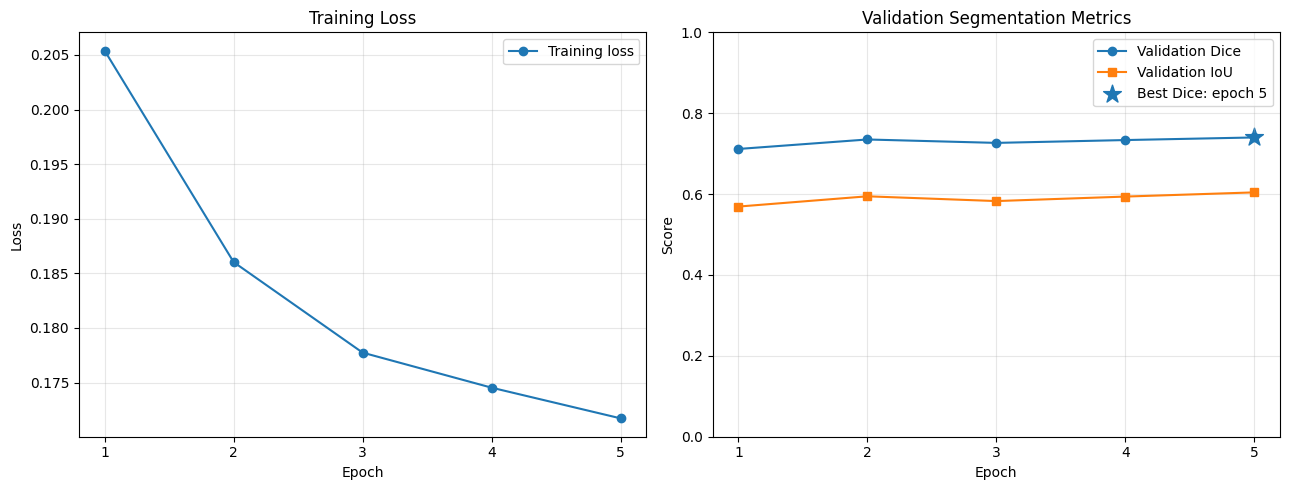

Best validation Dice: 0.7400 at epoch 5
Validation IoU at that epoch: 0.6042
Final training loss: 0.1717


In [21]:

# Section 10.1: Visualize training progress across all saved epochs.
# This cell only plots saved results; it does not train or evaluate the model.

import matplotlib.pyplot as plt

# Extract epoch numbers and metrics from the saved history.
epochs = [record["epoch"] for record in history]
training_losses = [
    record["training"]["loss"] for record in history
]
validation_dice = [
    record["validation"]["mean_dice"] for record in history
]
validation_iou = [
    record["validation"]["mean_iou"] for record in history
]

# Identify the epoch with the highest mean validation Dice.
best_index = max(
    range(len(validation_dice)),
    key=lambda index: validation_dice[index],
)
best_epoch = epochs[best_index]
best_dice = validation_dice[best_index]
best_iou = validation_iou[best_index]

# Plot training loss separately from validation metrics because
# they measure different things and use different scales.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: training loss should generally decrease as learning progresses.
axes[0].plot(
    epochs, training_losses,
    marker="o", label="Training loss"
)
axes[0].set_title("Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].set_xticks(epochs)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Right: higher Dice and IoU indicate better mask overlap.
axes[1].plot(
    epochs, validation_dice,
    marker="o", label="Validation Dice"
)
axes[1].plot(
    epochs, validation_iou,
    marker="s", label="Validation IoU"
)
axes[1].scatter(
    [best_epoch], [best_dice],
    marker="*", s=180,
    label=f"Best Dice: epoch {best_epoch}"
)
axes[1].set_title("Validation Segmentation Metrics")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].set_xticks(epochs)
axes[1].set_ylim(0, 1)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

# Print a concise summary for the experiment record.
print(f"Best validation Dice: {best_dice:.4f} at epoch {best_epoch}")
print(f"Validation IoU at that epoch: {best_iou:.4f}")
print(f"Final training loss: {training_losses[-1]:.4f}")


In [23]:

# Inspect saved validation metrics without printing all 200 per-image records.

print("Validation fields:")
print(list(history[0]["validation"].keys()))

print("\nValidation summary for each epoch:")
for record in history:
    validation = record["validation"]
    print(
        f"Epoch {record['epoch']}: "
        f"Dice={validation['mean_dice']:.4f}, "
        f"IoU={validation['mean_iou']:.4f}"
    )


Validation fields:
['mean_dice', 'median_dice', 'mean_iou', 'median_iou', 'mean_precision', 'median_precision', 'mean_recall', 'median_recall', 'n_evaluated', 'empty_true', 'empty_pred']

Validation summary for each epoch:
Epoch 1: Dice=0.7116, IoU=0.5691
Epoch 2: Dice=0.7350, IoU=0.5945
Epoch 3: Dice=0.7266, IoU=0.5827
Epoch 4: Dice=0.7336, IoU=0.5938
Epoch 5: Dice=0.7400, IoU=0.6042


### 8.2. Qualitative Validation: Ground Truth vs. Model Predictions

Quantitative metrics summarize segmentation performance, but visual inspection helps reveal where the model succeeds and where it struggles. This section compares original validation images with their ground-truth crack masks and predicted segmentation masks.

The best checkpoint is loaded from the saved experiment artifacts. Inference runs on the CPU to avoid dependence on GPU availability and **does not retrain or modify the model**.

**Evaluation boundary:** Only validation records are used in this section. The test set remains reserved for the final evaluation in Section 10.4.

Checkpoint: best_model.pth
Checkpoint epoch: 5
Inference device: CPU


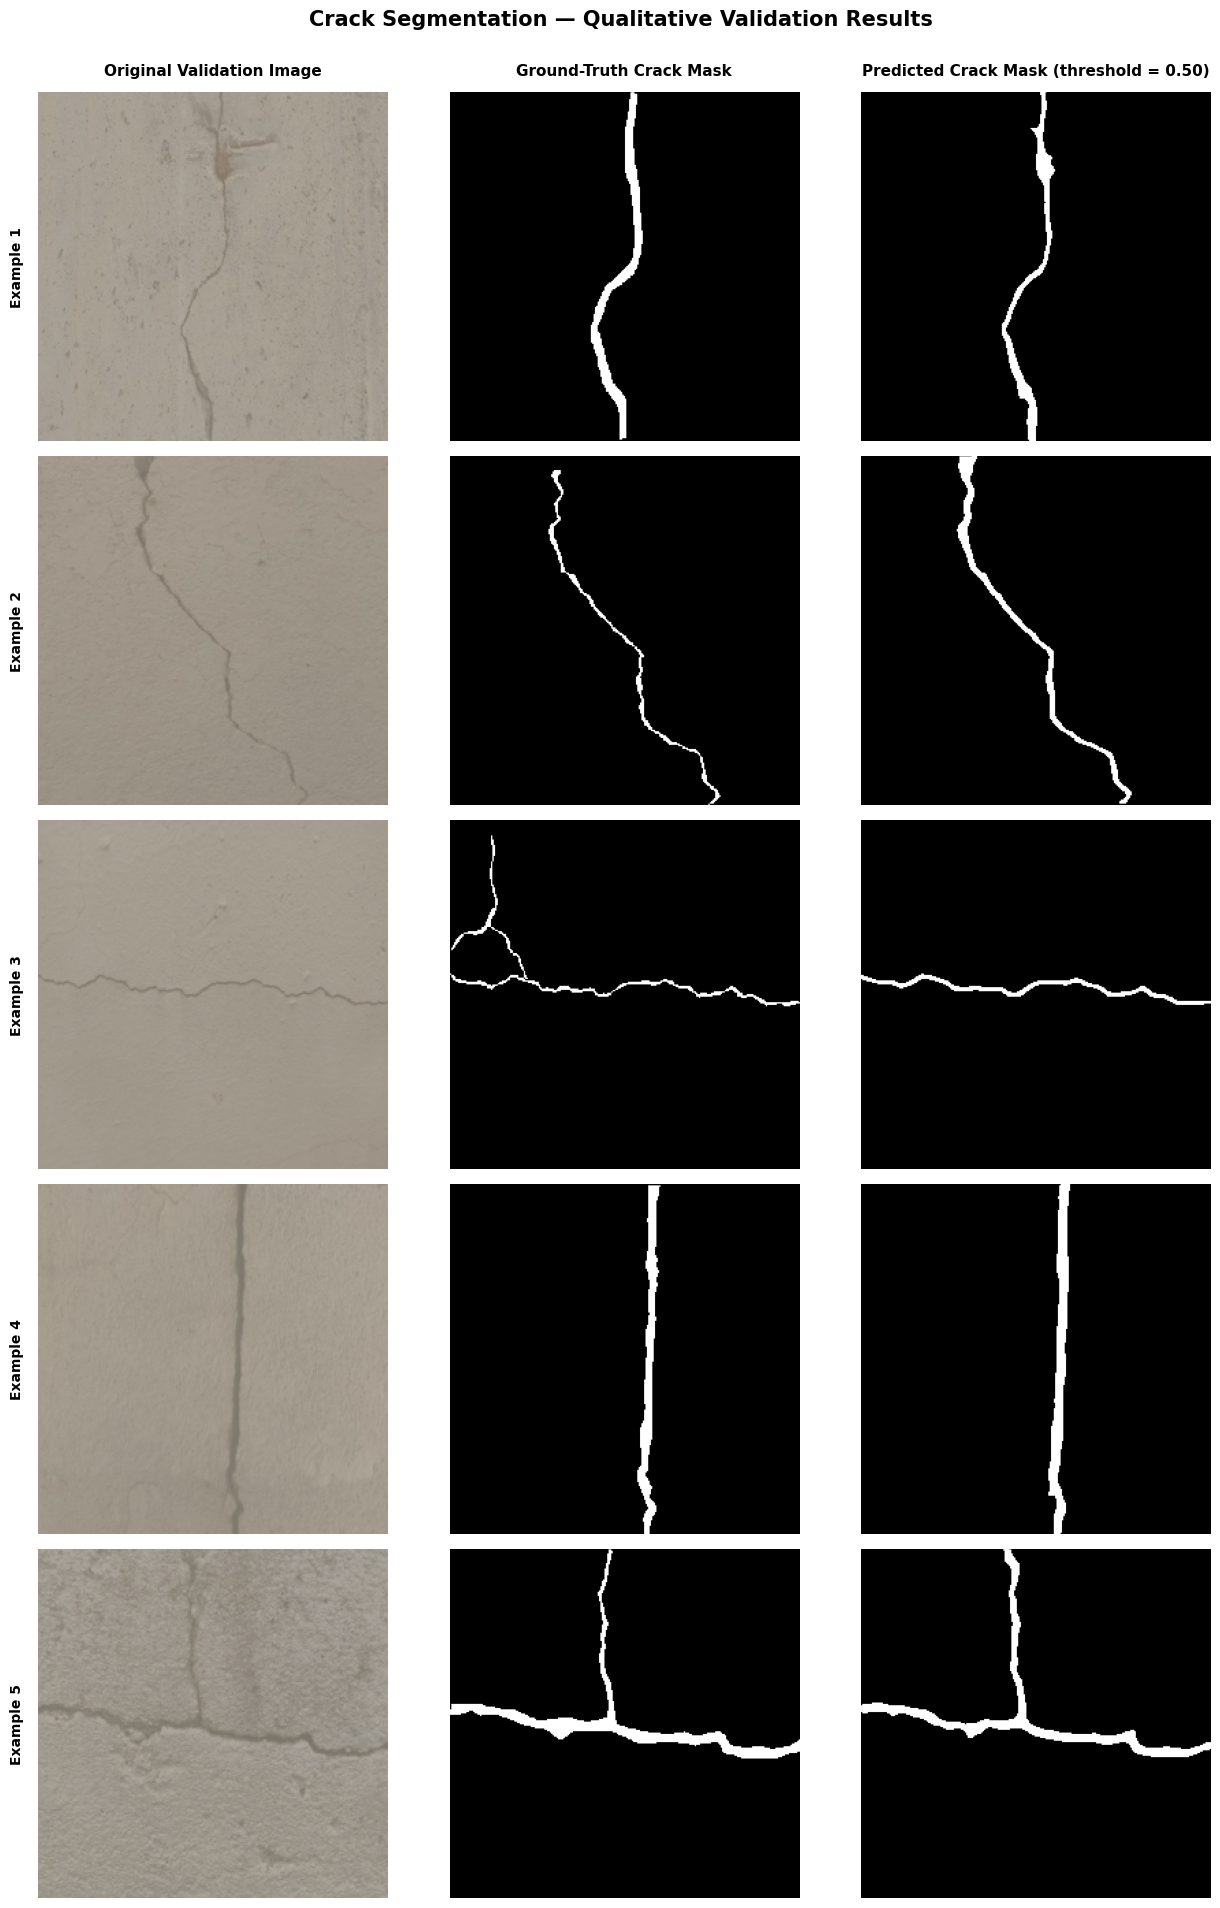

Validation examples displayed: 5
Ground-truth masks and predictions are shown at the model input resolution.
Reminder: these are qualitative validation examples, not final test results.


In [24]:
# Section 10.2: Qualitative inspection of validation predictions.
# This cell loads the saved best checkpoint and performs CPU-only inference.
# It does not train the model and does not access the test set.

import torch
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from crack_detection.model import build_model
from crack_detection.dataset_loader import SegmentationDataset

# ---------------------------------------------------------
# 1. Load the saved best checkpoint on CPU
# ---------------------------------------------------------
BEST_CHECKPOINT = EXPERIMENT_DIR / "checkpoints" / "best_model.pth"

if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(
        f"Best checkpoint not found: {BEST_CHECKPOINT}\n"
        "Check that Google Drive is mounted and the experiment path is correct."
    )

# Build the model architecture without downloading pretrained weights.
# The saved checkpoint supplies the trained parameters.
model, _ = build_model(pretrained=False, device_hint="cpu")

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to("cpu")
model.eval()

checkpoint_epoch = checkpoint.get("epoch", "unknown")
print(f"Checkpoint: {BEST_CHECKPOINT.name}")
print(f"Checkpoint epoch: {checkpoint_epoch}")
print("Inference device: CPU")

# ---------------------------------------------------------
# 2. Select validation records only
# ---------------------------------------------------------
validation_records = resolved_records["val"]

if len(validation_records) == 0:
    raise ValueError("The validation split contains no records.")

# Use a fixed seed so the selected examples remain reproducible.
rng = np.random.default_rng(42)
num_examples = min(5, len(validation_records))
selected_indices = sorted(
    rng.choice(len(validation_records), size=num_examples, replace=False).tolist()
)
selected_records = [validation_records[i] for i in selected_indices]

validation_dataset = SegmentationDataset(
    selected_records,
    dataset_name="crack-seg",
    image_size=(256, 256),
    augment=False,
    project_root=PROJECT_DIR,
)

# ---------------------------------------------------------
# 3. Predict masks and prepare presentation-quality figures
# ---------------------------------------------------------
def image_to_display(image_tensor):
    """Convert a normalized CHW image tensor into a displayable RGB image."""
    image = image_tensor.detach().cpu().float()

    # ImageNet normalization is used by the pretrained ResNet encoder.
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    image = image * std + mean
    image = image.clamp(0, 1)

    return image.permute(1, 2, 0).numpy()


predictions = []

with torch.inference_mode():
    for index in range(len(validation_dataset)):
        sample = validation_dataset[index]

        image_tensor = sample["image"].unsqueeze(0).to("cpu")
        true_mask = sample["mask"].squeeze().cpu().numpy()

        logits = model(image_tensor)
        probabilities = torch.sigmoid(logits)[0, 0].cpu().numpy()
        predicted_mask = (probabilities >= 0.5).astype(np.uint8)

        predictions.append({
            "image": image_to_display(sample["image"]),
            "true_mask": true_mask,
            "predicted_mask": predicted_mask,
            "probabilities": probabilities,
        })

# ---------------------------------------------------------
# 4. Plot original image, ground truth, and prediction
# ---------------------------------------------------------
fig, axes = plt.subplots(
    nrows=num_examples,
    ncols=3,
    figsize=(13, 3.8 * num_examples),
    squeeze=False,
)

column_titles = [
    "Original Validation Image",
    "Ground-Truth Crack Mask",
    "Predicted Crack Mask (threshold = 0.50)",
]

for column, title in enumerate(column_titles):
    axes[0, column].set_title(title, fontsize=11, fontweight="bold", pad=12)

for row, result in enumerate(predictions):
    axes[row, 0].imshow(result["image"])
    axes[row, 1].imshow(result["true_mask"], cmap="gray", vmin=0, vmax=1)
    axes[row, 2].imshow(result["predicted_mask"], cmap="gray", vmin=0, vmax=1)

    axes[row, 0].set_ylabel(
        f"Example {row + 1}",
        fontsize=10,
        fontweight="bold",
        labelpad=10,
    )

    for column in range(3):
        axes[row, column].set_xticks([])
        axes[row, column].set_yticks([])
        for spine in axes[row, column].spines.values():
            spine.set_visible(False)

fig.suptitle(
    "Crack Segmentation — Qualitative Validation Results",
    fontsize=15,
    fontweight="bold",
    y=1.002,
)
fig.tight_layout()
plt.show()

print(f"Validation examples displayed: {num_examples}")
print("Ground-truth masks and predictions are shown at the model input resolution.")
print("Reminder: these are qualitative validation examples, not final test results.")

### 8.3 Final Test-Set Integrity and Exclusion Audit

Before final evaluation, verify that the test split contains the expected records and that the documented exact-duplicate exclusion is available.

The original Crack-Seg test split contained 112 records. One exact duplicate image was excluded, leaving **111 records intended for final scoring**. The exclusion is documented in `manifests/crackseg_duplicate_exclusion.json`.

Near-duplicate review has not been completed. This remains a dataset limitation and must be disclosed in the final report.

This section checks test-manifest integrity and exclusion metadata only. It does not run model inference or inspect test performance. Once this audit passes and the checkpoint and evaluation configuration are confirmed, the test set can be evaluated once in Section 10.4.

In [27]:
# Section 10.3: Final test-manifest integrity audit.
# Read-only: validates eligibility and locates the exclusion record.
# No model inference and no test metric calculation.

import json
from pathlib import Path

test_records = resolved_records["test"]

# ---------------------------------------------------------
# 1. Separate manifest records from eligible scoring records
# ---------------------------------------------------------
excluded_records = [
    record for record in test_records
    if record.get("excluded_from_scored_eval") is True
]

scored_test_records = [
    record for record in test_records
    if record.get("excluded_from_scored_eval") is not True
]

print("FINAL TEST-MANIFEST INTEGRITY AUDIT")
print("=" * 65)
print(f"Total test manifest records: {len(test_records)}")
print(f"Explicitly excluded records: {len(excluded_records)}")
print(f"Eligible records for scoring: {len(scored_test_records)}")

# Validate the expected dataset accounting.
assert len(test_records) == 112, (
    f"Expected 112 manifest records; found {len(test_records)}."
)
assert len(excluded_records) == 1, (
    f"Expected exactly one explicitly excluded record; found {len(excluded_records)}."
)
assert len(scored_test_records) == 111, (
    f"Expected 111 eligible records; found {len(scored_test_records)}."
)

# Verify the exclusion is specifically the documented exact duplicate.
excluded_record = excluded_records[0]

assert excluded_record.get("exclusion_reason") == "exact_duplicate_pair", (
    "The excluded record does not have the expected exclusion reason."
)

print("\nExcluded record:")
print("  Sample ID:", excluded_record.get("sample_id"))
print("  Reason:", excluded_record.get("exclusion_reason"))
print("  Excluded from scored evaluation:", excluded_record.get("excluded_from_scored_eval"))

# ---------------------------------------------------------
# 2. Locate the audit file without assuming the wrong root
# ---------------------------------------------------------
audit_candidates = [
    DRIVE_ROOT / "CrackDetection" / "manifests" / "crackseg_duplicate_exclusion.json",
    PROJECT_DIR.parent / "manifests" / "crackseg_duplicate_exclusion.json",
    PROJECT_DIR / "manifests" / "crackseg_duplicate_exclusion.json",
]

# Remove duplicate paths while preserving order.
audit_candidates = list(dict.fromkeys(path.resolve() for path in audit_candidates))
existing_audits = [path for path in audit_candidates if path.is_file()]

print("\nDuplicate-exclusion audit file:")
if existing_audits:
    for audit_path in existing_audits:
        print("  Found:", audit_path)
        with audit_path.open("r", encoding="utf-8") as file:
            audit_data = json.load(file)
        print("  JSON validity: passed")
        print("  Audit fields:", list(audit_data) if isinstance(audit_data, dict) else type(audit_data).__name__)
else:
    print("  NOT FOUND at the expected candidate paths.")
    print("  Candidate locations checked:")
    for path in audit_candidates:
        print("   -", path)

print("\nAudit conclusion:")
print("  Manifest accounting: 112 total = 111 eligible + 1 excluded.")
print("  Test inference performed: No")
print("  Test metrics calculated: No")
print("  Near-duplicate review: Still outstanding")

FINAL TEST-MANIFEST INTEGRITY AUDIT
Total test manifest records: 112
Explicitly excluded records: 1
Eligible records for scoring: 111

Excluded record:
  Sample ID: 1979.rf.dea5db582b997afc4acb0f68d74c3b84
  Reason: exact_duplicate_pair
  Excluded from scored evaluation: True

Duplicate-exclusion audit file:
  Found: /content/drive/MyDrive/CrackDetection/manifests/crackseg_duplicate_exclusion.json
  JSON validity: passed
  Audit fields: ['dataset', 'digests', 'evidence', 'excluded_sample', 'exclusion_reason', 'file_pair', 'retained_sample', 'scored_test_count_after_exclusion']

Audit conclusion:
  Manifest accounting: 112 total = 111 eligible + 1 excluded.
  Test inference performed: No
  Test metrics calculated: No
  Near-duplicate review: Still outstanding


### 8.4. One-Time Final Test Evaluation

The model checkpoint was selected using validation performance. The final test split is reserved for an unbiased assessment of the selected model and will not be used for hyperparameter tuning or checkpoint selection.

The test manifest contains 112 records. One byte-identical duplicate image is explicitly excluded, leaving **111 eligible test records**. The excluded record remains in the manifest for traceability but is not scored.

The evaluation will report aggregate segmentation metrics and the number of evaluated samples. Results will be interpreted in the context of the dataset and its limitations, including the outstanding near-duplicate review.

**Protocol:** load the saved best checkpoint, run inference once over the eligible test records, calculate the predefined metrics, save the results, and do not modify the model based on test performance.

In [28]:
# Section 10.4A: Final evaluation preflight.
# This cell does not run inference or calculate test metrics.

from pathlib import Path
import inspect

BEST_CHECKPOINT = EXPERIMENT_DIR / "checkpoints" / "best_model.pth"

# Only include records explicitly eligible for scored evaluation.
scored_test_records = [
    record
    for record in resolved_records["test"]
    if record.get("excluded_from_scored_eval") is not True
]

assert BEST_CHECKPOINT.is_file(), (
    f"Best checkpoint not found: {BEST_CHECKPOINT}"
)
assert len(scored_test_records) == 111, (
    f"Expected 111 eligible test records, found {len(scored_test_records)}."
)
assert len(resolved_records["test"]) == 112

# Inspect the project's existing metric implementation.
import crack_detection.train_loop as train_loop_module

metric_candidates = [
    name for name in dir(train_loop_module)
    if any(term in name.lower() for term in ("metric", "dice", "iou", "evaluate"))
]

print("FINAL EVALUATION PREFLIGHT")
print("=" * 60)
print(f"Checkpoint exists: {BEST_CHECKPOINT}")
print(f"Checkpoint size: {BEST_CHECKPOINT.stat().st_size:,} bytes")
print(f"Total manifest records: {len(resolved_records['test'])}")
print(f"Eligible test records: {len(scored_test_records)}")
print(f"Excluded records: {len(resolved_records['test']) - len(scored_test_records)}")
print(f"Metric-related names in train_loop: {metric_candidates}")

print("\nExisting validation function signature:")
print(inspect.signature(train_loop_module.validate_epoch))

print("\nPreflight complete. No test predictions or metrics have been calculated.")

FINAL EVALUATION PREFLIGHT
Checkpoint exists: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/checkpoints/best_model.pth
Checkpoint size: 283,837,248 bytes
Total manifest records: 112
Eligible test records: 111
Excluded records: 1
Metric-related names in train_loop: ['compute_metrics']

Existing validation function signature:
(model: torch.nn.modules.module.Module, loader: torch.utils.data.dataloader.DataLoader, device: torch.device) -> Tuple[Dict[str, float], list]

Preflight complete. No test predictions or metrics have been calculated.


In [30]:
# Section 10.4: One-time final test evaluation.
#
# Protocol:
# - Load the selected best checkpoint; do not train.
# - Score only records eligible for evaluation.
# - Reuse the project's existing validate_epoch metric implementation.
# - Save aggregate and per-image results for reproducibility.
# - Do not use test results for model selection or tuning.

import json
import time
from datetime import datetime, timezone
from pathlib import Path

import torch
from torch.utils.data import DataLoader

from crack_detection.model import build_model
from crack_detection.dataset_loader import SegmentationDataset
from crack_detection.train_loop import validate_epoch

# ---------------------------------------------------------
# 1. Confirm the final evaluation inputs
# ---------------------------------------------------------
BEST_CHECKPOINT = EXPERIMENT_DIR / "checkpoints" / "best_model.pth"
TEST_REPORT_PATH = EXPERIMENT_DIR / "final_test_report.json"

all_test_records = resolved_records["test"]

# Keep excluded records in the manifest for traceability,
# but do not include them in scored evaluation.
scored_test_records = [
    record for record in all_test_records
    if record.get("excluded_from_scored_eval") is not True
]

assert BEST_CHECKPOINT.is_file(), (
    f"Selected checkpoint not found: {BEST_CHECKPOINT}"
)
assert len(all_test_records) == 112, (
    f"Expected 112 total test manifest records, got {len(all_test_records)}."
)
assert len(scored_test_records) == 111, (
    f"Expected 111 eligible test records, got {len(scored_test_records)}."
)

# ---------------------------------------------------------
# 2. Prepare the CPU model and test loader
# ---------------------------------------------------------
device = torch.device("cpu")

model, _ = build_model(pretrained=False, device_hint="cpu")
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
    weights_only=False,
)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)
model.eval()

test_dataset = SegmentationDataset(
    scored_test_records,
    dataset_name="crack-seg",
    image_size=(256, 256),
    augment=False,
    project_root=PROJECT_DIR,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    collate_fn=experiment_collate_fn,
)

# ---------------------------------------------------------
# 3. Run final evaluation once
# ---------------------------------------------------------
print("FINAL TEST EVALUATION")
print("=" * 60)
print(f"Checkpoint: {BEST_CHECKPOINT}")
print(f"Checkpoint epoch: {checkpoint.get('epoch', 'unknown')}")
print(f"Device: {device}")
print(f"Total test manifest records: {len(all_test_records)}")
print(f"Excluded records: {len(all_test_records) - len(scored_test_records)}")
print(f"Records intended for scoring: {len(scored_test_records)}")
print("\nRunning evaluation. Do not interrupt this cell.")

started_at = time.time()

# Existing project implementation:
# - sigmoid threshold > 0.5
# - per-image Dice, IoU, precision, and recall
# - aggregate means and medians
aggregate_metrics, per_image_metrics = validate_epoch(
    model=model,
    loader=test_loader,
    device=device,
)

elapsed_seconds = time.time() - started_at

# ---------------------------------------------------------
# 4. Verify evaluated count before saving results
# ---------------------------------------------------------
actual_evaluated = aggregate_metrics["n_evaluated"]

if actual_evaluated != len(scored_test_records):
    raise RuntimeError(
        f"Evaluation count mismatch: expected {len(scored_test_records)}, "
        f"but validate_epoch evaluated {actual_evaluated}. "
        "Do not report these results as final."
    )

# ---------------------------------------------------------
# 5. Save an auditable JSON report
# ---------------------------------------------------------
def json_safe_record(record):
    """Convert a record into JSON-compatible values."""
    safe = {}
    for key, value in record.items():
        if isinstance(value, Path):
            safe[key] = str(value)
        elif isinstance(value, (str, int, float, bool)) or value is None:
            safe[key] = value
        else:
            safe[key] = str(value)
    return safe

report = {
    "experiment": EXPERIMENT_DIR.name,
    "evaluation_type": "one_time_final_test_evaluation",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "checkpoint_path": str(BEST_CHECKPOINT),
    "checkpoint_epoch": checkpoint.get("epoch"),
    "device": str(device),
    "image_size": [256, 256],
    "prediction_threshold": 0.5,
    "metric_aggregation": "per-image metrics, summarized by mean and median",
    "test_manifest_records": len(all_test_records),
    "excluded_record_count": len(all_test_records) - len(scored_test_records),
    "eligible_test_records": len(scored_test_records),
    "actual_evaluated_records": actual_evaluated,
    "elapsed_seconds": round(elapsed_seconds, 2),
    "aggregate_metrics": aggregate_metrics,
    "per_image_metrics": [
        {
            **{
                key: value
                for key, value in metric.items()
                if key != "record"
            },
            "record": json_safe_record(metric["record"])
            if isinstance(metric.get("record"), dict)
            else str(metric.get("record")),
        }
        for metric in per_image_metrics
    ],
    "limitations": [
        "Near-duplicate review has not been completed.",
        "Results apply to this dataset and evaluation protocol; "
        "they do not independently establish structural safety or crack severity."
    ],
}

with TEST_REPORT_PATH.open("w", encoding="utf-8") as file:
    json.dump(report, file, indent=2, ensure_ascii=False)

# ---------------------------------------------------------
# 6. Present a concise, report-ready summary
# ---------------------------------------------------------
print("\nFINAL TEST RESULTS")
print("=" * 60)

for metric_name in ("dice", "iou", "precision", "recall"):
    print(
        f"Mean {metric_name.title():<10}: "
        f"{aggregate_metrics[f'mean_{metric_name}']:.4f}"
    )
    print(
        f"Median {metric_name.title():<10}: "
        f"{aggregate_metrics[f'median_{metric_name}']:.4f}"
    )

print(f"\nActual evaluated records: {actual_evaluated}")
print(f"Empty ground-truth masks: {aggregate_metrics['empty_true']}")
print(f"Empty predicted masks: {aggregate_metrics['empty_pred']}")
print(f"Evaluation duration: {elapsed_seconds / 60:.2f} minutes")
print(f"Saved report: {TEST_REPORT_PATH}")
print("\nEvaluation completed. Do not use these test results to tune the model.")

FINAL TEST EVALUATION
Checkpoint: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/checkpoints/best_model.pth
Checkpoint epoch: 5
Device: cpu
Total test manifest records: 112
Excluded records: 1
Records intended for scoring: 111

Running evaluation. Do not interrupt this cell.

FINAL TEST RESULTS
Mean Dice      : 0.7242
Median Dice      : 0.7630
Mean Iou       : 0.5884
Median Iou       : 0.6168
Mean Precision : 0.7379
Median Precision : 0.7622
Mean Recall    : 0.7758
Median Recall    : 0.8427

Actual evaluated records: 111
Empty ground-truth masks: 0
Empty predicted masks: 0
Evaluation duration: 1.51 minutes
Saved report: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/final_test_report.json

Evaluation completed. Do not use these test results to tune the model.


# 9. Results and Discussion

## Experiment Summary

The experiment evaluated a ResNet-34 U-Net model for binary crack segmentation on the Crack-Seg dataset. The model was trained for five epochs at an input resolution of 256 × 256 pixels, using a pretrained encoder and a combined Binary Cross-Entropy and Dice loss.

The best checkpoint was selected using validation Dice. Final test evaluation was then performed using the saved checkpoint and the existing project metric implementation.

| Experiment detail | Result |
|---|---|
| Experiment | M3 Crack-Seg Baseline B1 |
| Model | ResNet-34 U-Net |
| Input resolution | 256 × 256 |
| Training epochs completed | 5 |
| Best checkpoint | Epoch 5 |
| Best validation Dice | 0.7400 |
| Test manifest records | 112 |
| Exact duplicate excluded | 1 |
| Eligible test images evaluated | 111 |
| Evaluation device | CPU |

## Final Test Performance

The final evaluation produced a mean Dice score of 0.7242 and a mean Intersection over Union (IoU) of 0.5884 across 111 eligible test images.

Mean precision was 0.7379, while mean recall was 0.7758. The higher recall indicates that, on average, the model captured a greater proportion of reference crack pixels than its precision alone would suggest. However, the aggregate metrics do not reveal how performance varies across crack widths, surface textures, lighting conditions, or structural components.

The median Dice score (0.7630) was higher than the mean Dice score (0.7242). This indicates that the distribution of per-image results warrants further examination; the summary alone does not establish the cause of the difference.

## Validation and Test Comparison

The best validation Dice was 0.7400 at epoch 5, compared with a final test mean Dice of 0.7242. The difference is approximately 0.0158.

This difference is descriptive, not proof of overfitting. Validation and test performance can differ because of sampling variability, image difficulty, and differences in the examples represented by each split.

The test results are retained as the baseline reference. They must not be used to select hyperparameters or modify this checkpoint.

## Limitations

1. **Dataset scope:** The current experiment evaluates the Crack-Seg dataset. Its results do not establish generalization to all painted walls, beams, columns, building materials, or field-inspection conditions.
2. **Near-duplicate review:** One byte-identical duplicate was excluded from scored evaluation, but the planned near-duplicate review remains incomplete.
3. **Segmentation only:** The model predicts binary crack masks. It does not yet measure crack width in calibrated physical units or classify structural severity.
4. **No structural-safety determination:** Pixel-level segmentation metrics cannot establish whether a building element is safe or unsafe.
5. **Limited training schedule:** The baseline used five epochs. The result should be treated as an initial reference, not evidence that training or model development is complete.
6. **Metric limitations:** Aggregate scores can conceal poor performance on particular images or crack types. Per-image errors and representative failure cases require further analysis.

## Conclusion

This experiment establishes a reproducible baseline for automated crack segmentation. The selected checkpoint achieved a mean test Dice of 0.7242 and mean IoU of 0.5884 across 111 eligible test images.

The next stage should focus on understanding segmentation failures, improving dataset quality and diversity, and evaluating generalization. Crack measurement and severity assessment should be developed and validated as separate capabilities before the system is presented as a practical building-inspection product.

**Baseline status:** Final test evaluation completed. Checkpoint preserved. Near-duplicate review and subsequent model-development work remain outstanding.

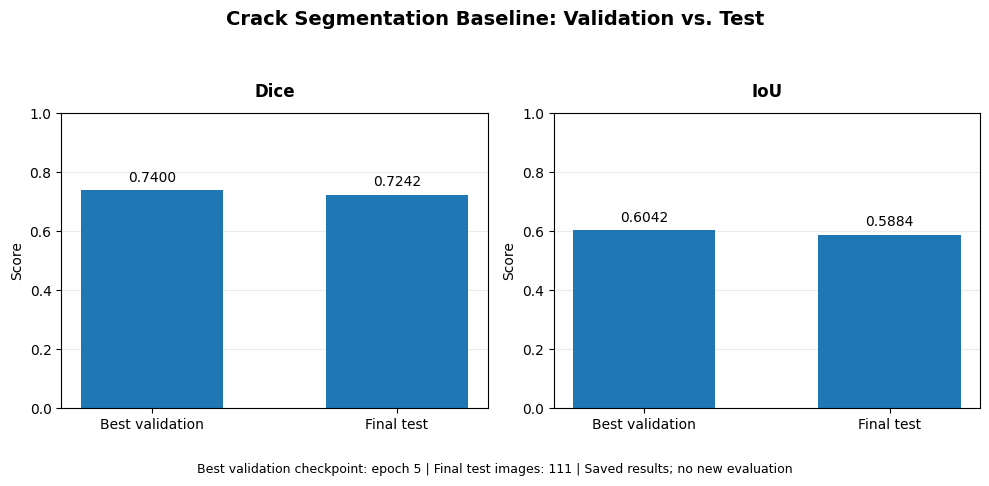

Saved report: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/final_test_report.json
This figure compares saved validation and test metrics only.


In [31]:
import json
import matplotlib.pyplot as plt
from pathlib import Path

# Load the previously saved final test report.
report_path = EXPERIMENT_DIR / "final_test_report.json"

with report_path.open("r", encoding="utf-8") as file:
    final_report = json.load(file)

# Identify the best epoch from the recorded validation history.
best_validation_record = max(
    history,
    key=lambda record: record["validation"]["mean_dice"],
)

best_epoch = best_validation_record["epoch"]
validation_dice = best_validation_record["validation"]["mean_dice"]
validation_iou = best_validation_record["validation"]["mean_iou"]

test_metrics = final_report["aggregate_metrics"]
test_dice = test_metrics["mean_dice"]
test_iou = test_metrics["mean_iou"]

# Create a presentation-ready comparison figure.
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8))

metric_groups = [
    ("Dice", validation_dice, test_dice),
    ("IoU", validation_iou, test_iou),
]

for ax, (metric_name, val_score, test_score) in zip(axes, metric_groups):
    bars = ax.bar(
        ["Best validation", "Final test"],
        [val_score, test_score],
        width=0.58,
    )

    ax.set_title(metric_name, fontweight="bold", pad=12)
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.bar_label(bars, fmt="%.4f", padding=4, fontsize=10)
    ax.tick_params(axis="x", labelrotation=0)

fig.suptitle(
    "Crack Segmentation Baseline: Validation vs. Test",
    fontsize=14,
    fontweight="bold",
)
fig.text(
    0.5,
    0.015,
    f"Best validation checkpoint: epoch {best_epoch} | "
    f"Final test images: {final_report['actual_evaluated_records']} | "
    "Saved results; no new evaluation",
    ha="center",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0.07, 1, 0.93])
plt.show()

print(f"Saved report: {report_path}")
print("This figure compares saved validation and test metrics only.")

# 10. Error Analysis

## Per-Image Performance Analysis

Aggregate metrics summarize overall performance but can conceal substantial variation between images. This analysis examines the saved per-image test metrics to identify difficult cases, variation in segmentation quality, and differences between precision and recall.

The analysis uses the completed final evaluation report. It does not retrain the model, rerun inference, or modify the selected checkpoint.

The test set remains an evaluation set, not a tuning set. Findings from this analysis will inform hypotheses for future experiments, which should be assessed using appropriately separated development and evaluation data.

**Scope:** Per-image metric analysis and record-level diagnostics. Predicted mask images were not saved in the current report, so pixel-level visual failure analysis is not available from this artifact alone.

In [32]:
# This cell reads the existing report only; it performs no inference.

import json
import pandas as pd
from pathlib import Path

REPORT_PATH = EXPERIMENT_DIR / "final_test_report.json"

if not REPORT_PATH.is_file():
    raise FileNotFoundError(f"Saved final test report not found: {REPORT_PATH}")

with REPORT_PATH.open("r", encoding="utf-8") as file:
    final_report = json.load(file)

per_image_records = final_report.get("per_image_metrics", [])

if not per_image_records:
    raise ValueError(
        "The final test report contains no per-image metrics. "
        "Stop here and inspect the saved report."
    )

# Flatten each metric record into a table suitable for analysis.
rows = []
for item in per_image_records:
    record_metadata = item.get("record", {})
    if not isinstance(record_metadata, dict):
        record_metadata = {}

    rows.append({
        "sample_id": record_metadata.get("sample_id", "unknown"),
        "image_path": record_metadata.get("image_path", ""),
        "dice": item.get("dice"),
        "iou": item.get("iou"),
        "precision": item.get("precision"),
        "recall": item.get("recall"),
        "empty_true": item.get("empty_true"),
        "empty_pred": item.get("empty_pred"),
    })

error_df = pd.DataFrame(rows)

metric_columns = ["dice", "iou", "precision", "recall"]
for column in metric_columns:
    error_df[column] = pd.to_numeric(error_df[column], errors="coerce")

print("SAVED TEST ERROR-ANALYSIS DATA")
print("=" * 65)
print(f"Report: {REPORT_PATH}")
print(f"Rows in per-image report: {len(error_df)}")
print(f"Expected evaluated test images: {final_report['actual_evaluated_records']}")
print(f"Duplicate-excluded records: {final_report['excluded_record_count']}")
print(f"Unique sample IDs: {error_df['sample_id'].nunique()}")

assert len(error_df) == final_report["actual_evaluated_records"], (
    "Per-image record count does not match the saved evaluation count."
)

display(error_df.head())

SAVED TEST ERROR-ANALYSIS DATA
Report: /content/drive/MyDrive/CrackDetection/outputs/experiments/m3_crack_seg_baseline_b1_20261026_201725/final_test_report.json
Rows in per-image report: 111
Expected evaluated test images: 111
Duplicate-excluded records: 1
Unique sample IDs: 111


,sample_id,image_path,dice,iou,precision,recall,empty_true,empty_pred
0,1616.rf.c868709931a671796794fdbb95352c5a,/content/drive/MyDrive/CrackDetection/data/cra...,0.682353,0.517857,0.681307,0.683402,0,0
1,1675.rf.e3aa3f8d28d0247ef0284dd46dacc29f,/content/drive/MyDrive/CrackDetection/data/cra...,0.608784,0.437591,0.670387,0.557550,0,0
2,1686.rf.809fb1b51c607e5cf787e44ef4ddd7b8,/content/drive/MyDrive/CrackDetection/data/cra...,0.763001,0.616816,0.955743,0.634952,0,0
3,1706.rf.011d213c21ec78896c36728dcbc156f5,/content/drive/MyDrive/CrackDetection/data/cra...,0.322801,0.192465,0.901471,0.196600,0,0
4,1716.rf.85ea38b36008beaa72c5d8541f734eb0,/content/drive/MyDrive/CrackDetection/data/cra...,0.660294,0.492864,0.722181,0.608176,0,0


### 10.2. Identify difficult cases and summarize metric variation.

Uses saved per-image metrics only.

PER-IMAGE METRIC DISTRIBUTION


,count,mean,std,min,10%,25%,50%,75%,90%,max
dice,111.0,0.7242,0.1623,0.0,0.5279,0.6610,0.7630,0.8291,0.8685,0.9465
iou,111.0,0.5884,0.1686,0.0,0.3586,0.4936,0.6168,0.7081,0.7676,0.8984
precision,111.0,0.7379,0.1996,0.0,0.5052,0.6251,0.7622,0.8867,0.9557,0.9961
recall,111.0,0.7758,0.2170,0.0,0.4430,0.6740,0.8427,0.9391,0.9729,1.0000



10 LOWEST-DICE TEST IMAGES


,sample_id,dice,iou,precision,recall
0,1839.rf.3495cbba8ee9a583ed0dff8d0e5fc0f7,0.0000,0.0000,0.0000,0.0000
1,3306.rf.b72adcdf677fa01eeccf1247826ff0d8,0.0015,0.0007,0.0011,0.0022
2,1921.rf.e704f0b0e352f4ac12f23e71ffa6d9ad,0.2366,0.1342,0.2296,0.2441
3,2240.rf.66f2163089851cb1d7874b913e592b94,0.3185,0.1894,0.1901,0.9820
4,1706.rf.011d213c21ec78896c36728dcbc156f5,0.3228,0.1925,0.9015,0.1966
5,1794.rf.7a03ca09d05e9e2941f768bc8570cb54,0.4933,0.3274,0.6608,0.3935
6,2454.rf.98ca60a89bb835f7ef56315930fdef1d,0.5106,0.3429,0.3429,1.0000
7,1974.rf.c900dacf421e72dd3b10be4d3f6e4b40,0.5161,0.3478,0.9888,0.3491
8,1813.rf.79f1af872f76dd8b46df4a83ed5f54c6,0.5227,0.3538,0.9875,0.3554
9,2412.rf.e84608f5da46f7643e7da0b7646e6db4,0.5248,0.3557,0.3593,0.9725


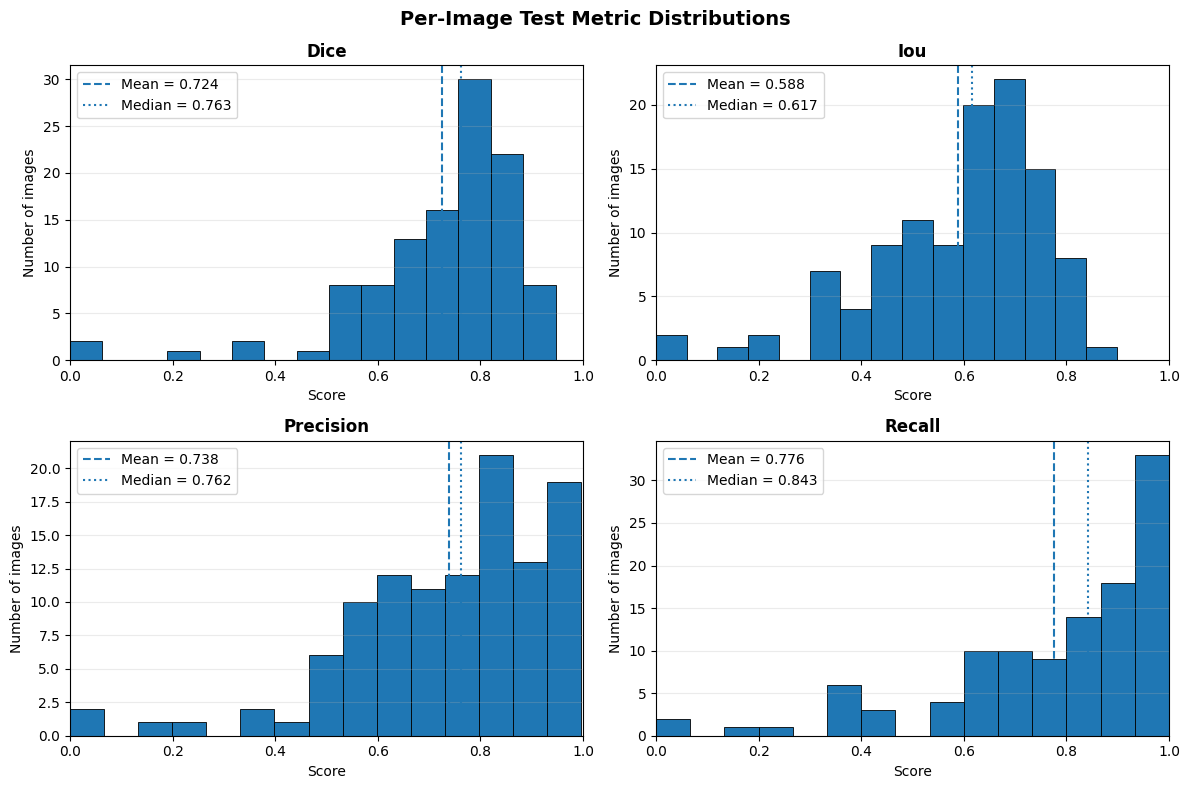

In [33]:
import matplotlib.pyplot as plt

summary = error_df[metric_columns].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).T

print("PER-IMAGE METRIC DISTRIBUTION")
print("=" * 65)
display(summary.round(4))

# Rank images by Dice; lower scores indicate weaker overlap.
worst_cases = (
    error_df.sort_values(["dice", "iou"], ascending=[True, True])
    .head(10)
    .copy()
)

print("\n10 LOWEST-DICE TEST IMAGES")
print("=" * 65)
display(
    worst_cases[
        ["sample_id", "dice", "iou", "precision", "recall"]
    ].round(4).reset_index(drop=True)
)

# Plot the distributions of the four saved metrics.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for ax, metric in zip(axes, metric_columns):
    values = error_df[metric].dropna()
    ax.hist(values, bins=15, edgecolor="black", linewidth=0.6)
    ax.axvline(
        values.mean(),
        linestyle="--",
        linewidth=1.5,
        label=f"Mean = {values.mean():.3f}",
    )
    ax.axvline(
        values.median(),
        linestyle=":",
        linewidth=1.5,
        label=f"Median = {values.median():.3f}",
    )
    ax.set_title(metric.replace("_", " ").title(), fontweight="bold")
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of images")
    ax.set_xlim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    ax.legend()

fig.suptitle(
    "Per-Image Test Metric Distributions",
    fontsize=14,
    fontweight="bold",
)
fig.tight_layout()
plt.show()

###  10.3. Error Pattern Classification

Categorize saved test results by the relationship between precision and recall.
This uses the existing report only; it does not run inference.


In [35]:

import numpy as np
import pandas as pd

def classify_error_pattern(row):
    precision = row["precision"]
    recall = row["recall"]
    dice = row["dice"]

    if dice < 0.05:
        return "Near-total failure"
    if precision < 0.50 and recall >= 0.80:
        return "Over-segmentation tendency"
    if precision >= 0.80 and recall < 0.50:
        return "Under-segmentation tendency"
    if precision < 0.50 and recall < 0.50:
        return "Low precision and recall"
    return "Mixed / moderate performance"

error_df["error_pattern"] = error_df.apply(
    classify_error_pattern, axis=1
)

pattern_counts = (
    error_df["error_pattern"]
    .value_counts()
    .rename_axis("error_pattern")
    .reset_index(name="image_count")
)

pattern_counts["percentage"] = (
    100 * pattern_counts["image_count"] / len(error_df)
).round(1)

display(pattern_counts)

print(f"Total scored test images: {len(error_df)}")
print(f"Mean test Dice: {error_df['dice'].mean():.4f}")


,error_pattern,image_count,percentage
0,Mixed / moderate performance,95,85.6
1,Under-segmentation tendency,8,7.2
2,Over-segmentation tendency,5,4.5
3,Near-total failure,2,1.8
4,Low precision and recall,1,0.9


Total scored test images: 111
Mean test Dice: 0.7242


### 10.4. Interpretation of Error Patterns

The per-image analysis identified variation in segmentation performance across the 111 eligible test images. Of these, 95 images (85.6%) were classified as mixed/moderate performance, eight (7.2%) showed an under-segmentation tendency, five (4.5%) showed an over-segmentation tendency, two (1.8%) were near-total failures, and one (0.9%) showed both low precision and low recall. These categories were assigned using predefined precision, recall, and Dice thresholds and should be interpreted as descriptive indicators rather than confirmed visual diagnoses.

Under-segmentation tendencies were more frequent than over-segmentation tendencies among the specifically classified error cases. This suggests that missed crack pixels are a useful hypothesis to investigate in future development experiments. However, the aggregate counts do not establish the cause of these errors. The saved evaluation report contains per-image metrics but does not preserve the predicted masks required for direct visual inspection of individual test failures.

The analysis used the completed evaluation report and did not retrain the model or rerun inference. The test set remains reserved for evaluation; the findings should guide hypotheses for future experiments rather than direct tuning against individual test images.

# 11. Model Development Summary and Next Steps

## Current Development Stage

This project is developing an AI-powered crack detection and severity assessment system for building inspection. The intended system will support the identification of cracks in building walls, beams, and columns, with future capabilities for crack measurement and severity assessment.

The current development stage focuses on training and evaluating the initial crack segmentation model. This model is responsible for identifying crack pixels in an input image, providing a foundation for subsequent crack analysis and measurement components.

The current model uses a ResNet34 encoder with a U-Net architecture. It was trained on the Crack-Seg dataset using 256 × 256 pixel images and a combined Binary Cross-Entropy and Dice loss.

## Current Model Performance

The best model checkpoint was selected based on validation performance at epoch 5. Evaluation on the eligible test images produced the following results:

| Performance metric | Result |
|---|---:|
| Mean Dice coefficient | 0.7242 |
| Median Dice coefficient | 0.7630 |
| Mean Intersection over Union (IoU) | 0.5884 |
| Mean precision | 0.7379 |
| Mean recall | 0.7758 |
| Test images evaluated | 111 |

These results provide the initial performance baseline for the crack segmentation component.

The mean recall of 0.7758 indicates that the model identifies a substantial proportion of the annotated crack pixels, while the mean precision of 0.7379 indicates that some predicted crack pixels do not correspond to the ground-truth annotations. The Dice and IoU results show that overlap between predicted and annotated crack regions still needs improvement.

Per-image analysis also identified cases of under-segmentation, over-segmentation, and near-total segmentation failure. These cases highlight the importance of improving reliability across different crack appearances rather than relying on aggregate metrics alone.

## Current System Limitations

The current implementation is a crack segmentation component, not yet a complete crack inspection system.

Its present limitations include:

- **Crack detection and segmentation:** The model predicts crack regions but has not yet been validated across the full range of building materials, surface conditions, lighting, and image-capture conditions expected in practical inspections.
- **Fine crack details:** The current 256 × 256 input resolution may limit the model's ability to preserve very thin cracks and small structural details.
- **Prediction review:** The saved evaluation report contains per-image metrics but not the predicted masks. Future evaluation runs should preserve prediction masks and visual overlays to support direct error inspection.
- **Dataset reliability:** One exact duplicate test image was excluded, leaving 111 eligible test images. Near-duplicate review remains incomplete.
- **Physical crack measurement:** Segmentation masks alone cannot provide reliable crack dimensions in millimetres without a suitable scale reference or camera-calibration method.
- **Severity assessment:** The current model does not classify crack severity or determine structural risk. Those capabilities require additional methods, appropriate reference data, and validation.
- **Structural safety:** The system has not been validated to determine whether a building or structural element is safe or unsafe.

## Next Development Steps

The next stages should build on the trained segmentation model in the following order.

1. **Improve crack segmentation.** Investigate failure cases, dataset quality, image resolution, augmentation, and suitable training configurations using training and validation data.
2. **Develop crack measurement.** Convert segmented crack regions into useful geometric measurements. Physical dimensions will require a reliable scale reference or calibration procedure.
3. **Develop severity assessment.** Establish a suitable assessment approach using relevant crack characteristics, inspection context, and expert-labeled examples. The current segmentation model alone cannot determine severity.
4. **Build the image-analysis workflow.** Connect image input, crack segmentation, visualization, measurement, and subsequent assessment into a coherent system.
5. **Validate under practical conditions.** Test the complete workflow on representative images of walls, beams, and columns, including painted surfaces and varying image quality.
6. **Add reliability and review mechanisms.** Identify uncertain or failed predictions and provide a path for human review instead of presenting every model output as reliable.
7. **Prepare for deployment.** After sufficient validation, assess inference speed, resource requirements, interface integration, and the handling of uploaded inspection images.

## Development Status

The initial crack segmentation training and evaluation phase is complete. The current checkpoint and evaluation report provide a baseline for subsequent development.

The next objective is to improve the segmentation component and then extend the system with crack measurement and severity assessment. These capabilities must be implemented and validated before the project can be considered a practical end-to-end crack inspection solution.

The intended outcome is an AI-assisted building inspection system that helps identify and analyse visible cracks. It should support, rather than replace, qualified professional judgement when evaluating structural significance and safety.